In [1]:
cd /home/sebastin/working/lab_lucac/sebastiN/projects/OCD_Symphony/notebooks

/home/sebastin/working/lab_lucac/sebastiN/projects/OCD_Symphony/notebooks


# fMRI Time Series Encoder

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse.csgraph import laplacian
from torch import eig
from scipy.linalg import eigh
from joblib import Parallel, delayed
from brainspace.gradient import GradientMaps



# Build gradients using diffusion maps and normalized angle
gm = GradientMaps(n_components=30, approach='dm', kernel='normalized_angle')




# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

##########################
# 1. Positional Encoding #
##########################
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, dim, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, dim, device=device)
        position = torch.arange(0, max_len, dtype=torch.float, device=device).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, dim, 2, device=device).float() * -(np.log(10000.0) / dim))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = pe.unsqueeze(0)  # Shape: (1, max_len, dim)
        self.alpha = nn.Parameter(torch.tensor(0.1))  # Initialized small
        self.ln = nn.LayerNorm(dim)
    def forward(self, x):
        """
        x: Shape (batch, time_steps, dim) -> Ensure the embedding dimension is correct
        """
        seq_len, embed_dim = x.shape[1], x.shape[2]
        # return self.ln(x + self.alpha * self.pe[:, :seq_len, :embed_dim].to(x.device))
        return x + self.pe[:, :seq_len, :embed_dim].to(x.device), self.pe[:, :seq_len, :embed_dim].to(x.device)



class RelativePositionalEncoding(nn.Module):
    def __init__(self, dim, max_len=200):
        super().__init__()
        self.rel_pos = nn.Parameter(torch.randn(2 * max_len - 1, dim))
        self.ln = nn.LayerNorm(dim)
        self.alpha = nn.Parameter(torch.tensor(0.1))

    def forward(self, x):
        B, T, D = x.shape
        indices = torch.arange(T, device=x.device)
        rel_indices = indices[None, :] - indices[:, None] + (T - 1)  # (T, T)
        rel_pe = self.rel_pos[rel_indices]  # (T, T, D)
        
        # print("temp att, ",x.mean(), x.std(), rel_pe.mean(), rel_pe.std())
        return self.ln(x + self.alpha * rel_pe.mean(dim=1))  # (B, T, D)



##########################
# 2. Learnable Positional Encoding #
#########################



class LearnablePosEncoding(nn.Module):
    def __init__(self, dim, max_len=5000):
        super().__init__()
        self.pe = nn.Parameter(torch.randn(1, max_len, dim))

    def forward(self, gm, x, fc_matrices=None):
        B, N, _ = x.shape
        return self.pe[:, :N, :].expand(B, N, -1)


class LearnablePositionalEncoding(nn.Module):
    def __init__(self, dim, max_len=5000):
        super().__init__()
        self.pe = nn.Parameter(torch.randn(1, max_len, dim))
        self.ln = nn.LayerNorm(dim)
        self.alpha = nn.Parameter(torch.tensor(0.1))

    def forward(self, gm, x, fc_matrices=None):
        B, N, _ = x.shape
        # print("spat att, ",x.mean(), x.std(), self.pe[:, :N, :].mean(), self.pe[:, :N, :].std())
        # return x + self.pe[:, :N, :].expand(B, N, -1)
        pe = self.pe[:, :x.size(1), :].expand(x.size(0), -1, -1)   
        # return self.ln(x + self.alpha * pe)
        return x + pe, pe
        


##############################
# 3 Functional Connectivity #
##############################
def compute_functional_connectivity(fmri_data):
    """
    fmri_data: Tensor of shape (subjects, ROIs, time_steps)
    Returns: Tensor of shape (subjects, ROIs, ROIs)
    """
    subject_fcs = []
    for subj_data in fmri_data:
        subj_data = subj_data.cpu().numpy()
        fc = np.corrcoef(subj_data)
        subject_fcs.append(fc)
    return torch.tensor(subject_fcs, dtype=torch.float32)
    return torch.from_numpy(np.array(subject_fcs)).float()






class BrainGradientPosEncoding(nn.Module):
    def __init__(self, dim, num_gradients=10, delta=0.5):
        super().__init__()
        self.num_gradients = num_gradients
        self.delta = delta
        self.proj = nn.Linear(self.num_gradients, dim)
        # self.gm = GradientMaps(n_components=self.num_gradients, approach='dm', kernel='normalized_angle')

    def forward(self, gm, x, fc_matrices):
        # G_proj = self.proj(gm.to(device))               # Shape: (B, N, dim)
        G_proj = self.proj(gm.to(self.proj.weight.device))  # ✅ always matches model's device
        return G_proj

class BrainGradientPositionalEncoding(nn.Module):
    def __init__(self, dim, num_gradients=10, delta=0.5):
        super().__init__()
        self.num_gradients = num_gradients
        self.delta = delta
        self.proj = nn.Linear(self.num_gradients, dim)
        self.ln = nn.LayerNorm(dim)
        self.alpha = nn.Parameter(torch.tensor(0.1))
        # self.gm = GradientMaps(n_components=self.num_gradients, approach='dm', kernel='normalized_angle')

    def forward(self, gm, x, fc_matrices):
        # G_proj = self.proj(gm.to(device))               # Shape: (B, N, dim)
        G_proj = self.proj(gm.to(self.proj.weight.device))  # ✅ always matches model's device
        return self.ln(x + self.alpha * G_proj), self.alpha * G_proj



class MixedPositionalEncoding(nn.Module):
    def __init__(self, full_dim, max_len=5000, num_gradients=10, delta=0.5):
        super().__init__()
        half_dim = full_dim // 2
        self.learnable_pe = LearnablePositionalEncoding(half_dim, max_len)
        self.gradient_pe = BrainGradientPositionalEncoding(half_dim, num_gradients, delta)

    def forward(self, gm, x, fc_matrices):
        B, N, D = x.shape
        pe_learnable = self.learnable_pe(gm, x, fc_matrices)
        pe_gradient = self.gradient_pe(gm, x, fc_matrices)
        pe = torch.cat([pe_learnable, pe_gradient], dim=-1)
        return x + pe



class FusedMixedPositionalEncoding(nn.Module):
    def __init__(self, full_dim, max_len=5000, num_gradients=10, delta=0.5):
        super().__init__()
        self.learnable_pe = LearnablePosEncoding(full_dim, max_len)
        self.gradient_pe = BrainGradientPosEncoding(full_dim, num_gradients, delta)
        self.ln = nn.LayerNorm(full_dim)
        self.alpha = nn.Parameter(torch.tensor(0.1))
        self.fusion_proj = nn.Sequential(
            nn.Linear(2 * full_dim, 2 * full_dim),
            nn.GELU(),
            nn.Linear(2 * full_dim, full_dim)
        )

    def forward(self, gm, x, fc_matrices):
        pe_learnable = self.learnable_pe(gm, x, fc_matrices)
        pe_gradient = self.gradient_pe(gm, x, fc_matrices)
        fused = torch.cat([pe_learnable, pe_gradient], dim=-1)
        # return self.ln(x + self.alpha * self.fusion_proj(fused)), self.alpha * self.fusion_proj(fused)
        return x + self.fusion_proj(fused), self.fusion_proj(fused)
        



class GraphPositionalEncoding(nn.Module):
    def __init__(self, fc_matrix, method='eigen'):
        super().__init__()
        self.method = method
        
        G = nx.from_numpy_array(fc_matrix.cpu().numpy())
        if method == 'eigen':
            eigenvectors = torch.tensor(nx.laplacian_spectrum(G)).float().to(device)
            self.pe = eigenvectors.unsqueeze(0)
        elif method == 'random_walk':
            rw_matrix = torch.tensor(nx.normalized_laplacian_matrix(G).toarray()).float().to(device)
            self.pe = rw_matrix.unsqueeze(0)
        else:
            raise ValueError("Unsupported graph-based positional encoding")
    
    def forward(self, x):
        return x + self.pe[:, :x.size(1)].to(x.device)

############################
# 4. Transformer Components #
############################
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim, num_heads):
        super().__init__()
        if dim % num_heads != 0:
            raise ValueError(f"dim ({dim}) should be divisible by num_heads ({num_heads})")

        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5 # Use exponentiation for scale

        # NO .to(device) here. Module creation stays on CPU initially.
        self.qkv = nn.Linear(dim, dim * 3, bias=False)
        self.fc_out = nn.Linear(dim, dim)

    def forward(self, x):
        B, T, C = x.shape # Batch, Sequence Length, Hidden Dimension

        qkv = self.qkv(x)  # (B, T, 3 * C)
        
        # Reshape and permute for multi-head operation
        qkv = qkv.reshape(B, T, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, B, num_heads, T, head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]  # each: (B, num_heads, T, head_dim)

        # Scaled Dot-Product Attention
        # (B, num_heads, T, head_dim) @ (B, num_heads, head_dim, T) -> (B, num_heads, T, T)
        attn_weights = (q @ k.transpose(-2, -1)) * self.scale # Use self.scale

        attn_weights = F.softmax(attn_weights, dim=-1)

        # Weighted sum of values
        # (B, num_heads, T, T) @ (B, num_heads, T, head_dim) -> (B, num_heads, T, head_dim)
        out = attn_weights @ v

        # Concatenate heads and apply final linear layer
        # (B, T, num_heads, head_dim) -> (B, T, C)
        out = out.transpose(1, 2).contiguous().reshape(B, T, C)
        out = self.fc_out(out)

        return out, attn_weights # Return attention output and weights




class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_dim, dropout=0.2):
        super().__init__()
        self.attn = MultiHeadSelfAttention(dim, num_heads)
        self.norm1 = nn.LayerNorm(dim) # NO .to(device) here
        self.norm2 = nn.LayerNorm(dim) # NO .to(device) here
        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, dim)
        ) # NO .to(device) here
        self.dropout = nn.Dropout(dropout) # NO .to(device) here

    def forward(self, x):
        # Multi-Head Self-Attention Block (Pre-Norm)
        # Apply LayerNorm before attention
        normed_x_attn = self.norm1(x)
        attn_output, attn_weights = self.attn(normed_x_attn)
        # Apply dropout to attention output, then add residual connection
        x = x + self.dropout(attn_output)

        # MLP Block (Pre-Norm)
        # Apply LayerNorm before MLP
        normed_x_mlp = self.norm2(x)
        mlp_output = self.mlp(normed_x_mlp)
        # Apply dropout to MLP output, then add residual connection
        x = x + self.dropout(mlp_output)
        
        return x, attn_weights





############################
# 5. Transformer Models #
############################
class TemporalTransformer(nn.Module):
    def __init__(self, num_layers, dim, num_heads, mlp_dim, time_steps, max_len):
        super().__init__()
        # self.cls_token = nn.Parameter(torch.randn(1, 1, dim))  # New CLS token
        self.layers = nn.ModuleList([TransformerBlock(dim, num_heads, mlp_dim) for _ in range(num_layers)])
        self.pos_enc = SinusoidalPositionalEncoding(dim, max_len)
        # self.pos_enc = RelativePositionalEncoding(dim, max_len)
        self.embedding_layer = nn.Linear(ROIs, dim)  # Ensure correct embedding dim
    
    def forward(self, x):
        """
        x: Shape (batch, ROIs, time_steps)
        - We transpose to (batch, time_steps, ROIs)
        - Apply embedding projection (ROIs → dim)
        - Apply positional encoding
        """
        x = x.transpose(1, 2)  # Shape: (batch, time_steps, ROIs)
        x = self.embedding_layer(x)  # Shape: (batch, time_steps, dim)
        B = x.size(0)
        x, raw_pe = self.pos_enc(x)  # Apply positional encoding

        
        
        # for layer in self.layers:
        #     x = layer(x)
        # return x  # Output: (batch, time_steps, dim)

        attn_weights_all = []
        for layer in self.layers:
            x, attn_weights = layer(x)
            attn_weights_all.append(attn_weights)
        return x, attn_weights_all, raw_pe









class SpatialTransformer(nn.Module):
    def __init__(self, num_layers, dim, num_heads, mlp_dim, time_steps, max_len, num_gradients, delta, pos_enc_type="learnable"):
        super().__init__()
        self.layers = nn.ModuleList([TransformerBlock(dim, num_heads, mlp_dim) for _ in range(num_layers)])
        self.embedding_layer = nn.Linear(time_steps, dim)
        

        if pos_enc_type == "learnable":
            self.pos_enc = LearnablePositionalEncoding(dim, max_len)
        elif pos_enc_type == "brain_gradient":
            self.pos_enc = BrainGradientPositionalEncoding(dim, num_gradients, delta)
        elif pos_enc_type == "mixed":
            assert dim % 2 == 0, "Dimension must be divisible by 2 for mixed encoding."
            self.pos_enc = FusedMixedPositionalEncoding(dim, max_len, num_gradients, delta)
        else:
            raise ValueError("Unknown positional encoding type")

        self.pos_enc_type = pos_enc_type
        # self.cls_token = nn.Parameter(torch.randn(1, 1, dim))

    def forward(self, gm, x, fc_matrices=None):
        x = self.embedding_layer(x)
        x, raw_pe = self.pos_enc(gm, x, fc_matrices)
        
        # for layer in self.layers:
        #     x = layer(x)
        # return x

        attn_weights_all = []
        for layer in self.layers:
            x, attn_weights = layer(x)
            attn_weights_all.append(attn_weights)
        return x, attn_weights_all, raw_pe




class PerceiverIODecoder(nn.Module):
    def __init__(self, input_dim, latent_dim=64, num_latents=32, signal_dim=8, num_queries=450*200, num_heads=2, dropout=0.0):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_latents = num_latents

        self.conv_signal = nn.Conv1d(in_channels=1, out_channels=signal_dim, kernel_size=5, padding=2)
        self.signal_dim = signal_dim

        self.gate_layer = nn.Linear(2 * input_dim, input_dim)  # input_dim = D


        # Learnable latent array (L, D)
        self.latents = nn.Parameter(torch.randn(num_latents, latent_dim))

        # Project ROI-time embeddings to latent dimension
        # self.input_proj = nn.Linear(2*input_dim, latent_dim)
        # self.input_proj = nn.Linear(2*input_dim + signal_dim, latent_dim)
        self.input_proj = nn.Linear(3*128, latent_dim)
        
        self.input_ln = nn.LayerNorm(latent_dim)


        # Cross-attention: latents query the input (fused ROI-Time embeddings)
        self.cross_attn = nn.MultiheadAttention(embed_dim=latent_dim, num_heads=num_heads, dropout=dropout, batch_first=True)

        # Latent processing block (can be stacked)
        self.latent_transformer = nn.TransformerEncoderLayer(
            d_model=latent_dim, nhead=num_heads, batch_first=True, dropout=dropout
        )

        # Output projection: output queries (R*T positions) attend to latents
        self.output_proj = nn.MultiheadAttention(embed_dim=latent_dim, num_heads=num_heads, dropout=dropout, batch_first=True)

        # Final head: map from latent to scalar value
        self.head = nn.Sequential(
            nn.Linear(latent_dim, latent_dim // 2),
            nn.GELU(),
            nn.Linear(latent_dim // 2, 1)
        )

        self.roi_proj = nn.Linear(256, 128)
        self.time_proj = nn.Linear(256, 128)
        self.signal_proj = nn.Linear(16, 128)

        self.decoding_queries = nn.Parameter(torch.randn(1, num_queries, latent_dim))  # e.g., num_queries = R*T





    def forward(self, roi_embeds, time_embeds, x):
        """
        roi_embeds: (B, R, D)
        time_embeds: (B, T, D)
        returns: reconstructed time series: (B, R, T)
        """
        B, R, D = roi_embeds.shape
        _, T, _ = time_embeds.shape

        # === Step 0: Compute signal context from input time series ===
                     
        signal_flat = x.contiguous().view(B * R, 1, T)        # (B*R, 1, T)
        signal_context = self.conv_signal(signal_flat)         # (B*R, d_signal, T)
        signal_context = signal_context.view(B, R, self.signal_dim, T)  # (B, R, d_signal, T)
        signal_context = signal_context.permute(0, 1, 3, 2)     # (B, R, T, d_signal)


        # === Step 1: Fuse ROI and Time ===
        roi_exp = roi_embeds.unsqueeze(2).expand(-1, -1, T, -1)   # (B, R, T, D)
        time_exp = time_embeds.unsqueeze(1).expand(-1, R, -1, -1) # (B, R, T, D)

        # gate = torch.sigmoid(self.gate_layer(torch.cat([roi_exp, time_exp], dim=-1)))
        # fused = gate * roi_exp + (1 - gate) * time_exp

        # fused = roi_exp + time_exp                                # (B, R, T, D)
        
        # fused = torch.cat([roi_exp, time_exp], dim=-1)  # (B, R, T, 2D)


        # fused = torch.cat([roi_exp, time_exp, signal_context], dim=-1)  # (B, R, T, 2D + d_signal)


        roi_proj = self.roi_proj(roi_exp)           # (B, R, T, 128)
        time_proj = self.time_proj(time_exp)        # (B, R, T, 128)
        signal_proj = self.signal_proj(signal_context)  # (B, R, T, 128)
        
        fused = torch.cat([roi_proj, time_proj, signal_proj], dim=-1)  # (B, R, T, 384)


        # fused = signal_context


        
        fused = fused.contiguous().view(B, R*T, -1)                             # (B, R*T, total_dim)

        # === Step 2: Project input to latent space ===
        # fused_proj = self.input_proj(fused)  # (B, R*T, latent_dim)
        fused_proj = self.input_ln(self.input_proj(fused))

        # === Step 3: Cross-attention (latents query input) ===
        latents = self.latents.unsqueeze(0).expand(B, -1, -1)  # (B, L, D)
        latents, _ = self.cross_attn(query=latents, key=fused_proj, value=fused_proj)  # (B, L, D)

        # === Step 4: Process latents ===
        latents = self.latent_transformer(latents)  # (B, L, D)

        # subject_embedding = latents.mean(dim=1)  # (B, D)
        # subject_embedding = nn.functional.normalize(subject_embedding, dim=-1)


        # === Step 5: Output queries (R*T) attend to latents ===
        # decoding_queries = fused_proj  # (B, R*T, D)
        # decoding_queries = signal_proj.contiguous().view(B, R*T, -1)   # (B, R*T, D)
        decoding_queries = self.decoding_queries.expand(B, R*T, -1)

        recon_tokens, _ = self.output_proj(query=decoding_queries, key=latents, value=latents)  # (B, R*T, D)

        

        # === Step 6: Final scalar regression per token ===
        recon_flat = self.head(recon_tokens)  # (B, R*T, 1)
        recon = recon_flat.view(B, R, T)      # (B, R, T)

        return recon, latents




######################
# 7. Full Model #
######################



class ROIWiseTransformer(nn.Module):
    def __init__(self, num_layers, dim, num_heads, mlp_dim, time_steps, max_len_temp, max_len_spatial, num_gradients, delta, spatial_pos_enc_type="learnable"):
        super().__init__()
        self.temporal_transformer = TemporalTransformer(num_layers, dim, num_heads, mlp_dim, time_steps, max_len_temp)
        
        # Pass fc_tensor to spatial transformer for brain gradient positional encoding
        self.spatial_transformer = SpatialTransformer(
            num_layers=num_layers,
            dim=dim,
            num_heads=num_heads,
            mlp_dim=mlp_dim,
            time_steps=time_steps,
            max_len=max_len_spatial,
            num_gradients = num_gradients,
            delta = delta,
            pos_enc_type = spatial_pos_enc_type
        )

        self.cross_attn_r2t = CrossAttentionFusion(dim, num_heads)
        self.cross_attn_t2r = CrossAttentionFusion(dim, num_heads)


        self.decoder = PerceiverIODecoder(input_dim=dim, latent_dim=128, num_latents=64, signal_dim=16,num_queries=450*200, num_heads=2)
        

        
    def forward(self, gm, x, fc_batch):
        """
        x: (batch, ROIs, time_steps)
        - Temporal Transformer: (batch, time_steps, ROIs) → (batch, time_steps, dim)
        - Spatial Transformer: (batch, ROIs, time_steps) → (batch, ROIs, dim)
        - Bilinear Decoder: Maps (batch, ROIs, dim) and (batch, time_steps, dim) → (batch, ROIs, time_steps)
        """
  

        time_embeds, temporal_attn_weights,_ = self.temporal_transformer(x)
        roi_embeds, spatial_attn_weights,_ = self.spatial_transformer(gm, x, fc_batch)

        reconstruction, subject_embedding = self.decoder(roi_embeds, time_embeds, x)



        return reconstruction, roi_embeds, time_embeds, spatial_attn_weights, temporal_attn_weights, subject_embedding




class SpatiotemporalMasker(nn.Module):
    def __init__(self, block_size=10, num_blocks=20):
        super().__init__()
        self.block_size = block_size
        self.num_blocks = num_blocks

    def forward(self, x):
        B, R, T = x.shape
        mask = torch.ones((B, R, T), device=x.device)

        # Generate random start indices for each block in each batch
        r_starts = torch.randint(0, R - self.block_size + 1, (B, self.num_blocks), device=x.device)
        t_starts = torch.randint(0, T - self.block_size + 1, (B, self.num_blocks), device=x.device)

        # Generate relative block indices
        r_offsets = torch.arange(self.block_size, device=x.device).view(1, 1, -1)  # (1, 1, block_size)
        t_offsets = torch.arange(self.block_size, device=x.device).view(1, 1, -1)  # (1, 1, block_size)

        # Compute full mask indices
        r_idx = r_starts.unsqueeze(-1) + r_offsets  # (B, num_blocks, block_size)
        t_idx = t_starts.unsqueeze(-1) + t_offsets  # (B, num_blocks, block_size)

        # Broadcast to get all (r, t) coordinate pairs per block
        r_idx = r_idx.unsqueeze(-1).expand(-1, -1, -1, self.block_size)  # (B, num_blocks, block_size, block_size)
        t_idx = t_idx.unsqueeze(-2).expand(-1, -1, self.block_size, -1)  # (B, num_blocks, block_size, block_size)

        # Flatten for advanced indexing
        r_idx = r_idx.reshape(B, -1)  # (B, num_blocks * block_size²)
        t_idx = t_idx.reshape(B, -1)  # (B, num_blocks * block_size²)
        b_idx = torch.arange(B, device=x.device).view(-1, 1).expand(-1, r_idx.size(1))  # (B, num_blocks * block_size²)

        # Set mask to zero at all block positions
        mask[b_idx, r_idx, t_idx] = 0
        return mask




class MaskedROIWiseTransformer(nn.Module):
    def __init__(self, fmri_encoder, masker, loss_fn=nn.MSELoss()):
        super().__init__()
        self.fmri_encoder = fmri_encoder
        self.masker = masker
        self.loss_fn = loss_fn

        # Learnable scalar token to replace masked values
        self.mask_token = nn.Parameter(torch.randn(1))

    def forward(self, gm, x, fc_batch):
        B, R, T = x.shape
        mask = self.masker(x)  # (B, R, T), 1 = visible, 0 = masked

        # Apply pairwise masking to the input values
        masked_x = x.clone()
        masked_x[mask == 0] = self.mask_token

       
        recon_x, roi_embeds, time_embeds,  spatial_attn_weights, temporal_attn_weights, subject_embedding = self.fmri_encoder(
            gm, masked_x, fc_batch
        )

        

      
        
        masked_loss = ((recon_x - x) * (1 - mask)).pow(2).sum() / (1 - mask).sum().clamp(min=1)
        visible_loss = ((recon_x - x) * mask).pow(2).sum() / mask.sum().clamp(min=1)
        
        loss =  visible_loss

        return loss, recon_x, mask, roi_embeds, time_embeds, spatial_attn_weights, temporal_attn_weights, subject_embedding





In [3]:
class TokenMasker1D(nn.Module):
    def __init__(self, mask_ratio=0.15):
        super().__init__()
        self.mask_ratio = mask_ratio

    def forward(self, x):
        B, R, T = x.shape
        mask = torch.ones((B, T), device=x.device)

        num_mask = int(self.mask_ratio * T)
        for b in range(B):
            idx = torch.randperm(T)[:num_mask]
            mask[b, idx] = 0
        return mask  # shape: (B, T)





class MaskedTemporalTransformer(nn.Module):
    def __init__(self, temporal_transformer, masker, roi_dim, hidden_dim=128, loss_fn=nn.MSELoss()):
        super().__init__()
        self.temporal_transformer = temporal_transformer
        self.masker = masker
        self.loss_fn = loss_fn
        self.mask_token = nn.Parameter(torch.randn(1, roi_dim))  # (1, R)

        latent_dim = temporal_transformer.layers[0].attn.qkv.in_features
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, roi_dim)
        )

    def forward(self, x):
        B, R, T = x.shape
        mask = self.masker(x)            # (B, T)
        mask_expanded = mask.unsqueeze(-1)  # (B, T, 1)

        x_transposed = x.transpose(1, 2)     # (B, T, R)
        masked_x = x_transposed * mask_expanded + (1 - mask_expanded) * self.mask_token  # (B, T, R)

        embedded, attn,temporal_pe = self.temporal_transformer(masked_x.transpose(1, 2))  # (B, T, D)

        recon = self.decoder(embedded)   # (B, T, R)
        recon = recon.transpose(1, 2)    # (B, R, T)

        mask_for_loss = mask[:, None, :]  # (B, 1, T)
        loss = ((recon - x) * (1 - mask_for_loss)).pow(2).sum() / ((R*(1 - mask_for_loss)).sum().clamp(min=1))

        return loss, recon, mask, attn, embedded, temporal_pe





class TokenMasker2D(nn.Module):
    def __init__(self, mask_ratio=0.15):
        super().__init__()
        self.mask_ratio = mask_ratio

    def forward(self, x):
        """
        x: (B, R, T)
        Returns: mask of shape (B, R), where 0 = masked, 1 = visible
        """
        B, R, T = x.shape
        mask = torch.ones((B, R), device=x.device)

        num_mask = int(self.mask_ratio * R)
        for b in range(B):
            idx = torch.randperm(R)[:num_mask]
            mask[b, idx] = 0

        return mask  # shape: (B, R)



class MaskedSpatialTransformer(nn.Module):
    def __init__(self, spatial_transformer, masker, time_steps, hidden_dim=128, loss_fn=nn.MSELoss()):
        super().__init__()
        self.spatial_transformer = spatial_transformer
        self.masker = masker
        self.loss_fn = loss_fn
        self.mask_token = nn.Parameter(torch.randn(1, time_steps))  # ✅ each masked ROI is replaced with (1, T)

        latent_dim = spatial_transformer.layers[0].attn.qkv.in_features

        # Decoder: latent D → original time series (T) per ROI
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, time_steps)
        )

    def forward(self, gm, x, fc_batch=None):
        """
        x: (B, R, T)
        """
        B, R, T = x.shape
        mask = self.masker(x)                # (B, R)
        mask_expanded = mask.unsqueeze(-1)   # (B, R, 1)

        mask_token = self.mask_token.to(x.device)  # move to the same device as x
        # Apply mask: masked ROIs get replaced by a learnable T-dim token

        masked_x = x * mask_expanded + (1 - mask_expanded) * mask_token



        # Forward through spatial transformer
        embedded, attn,spatial_pe = self.spatial_transformer(gm, masked_x, fc_batch)  # (B, R, D)

        # Decode to (B, R, T)
        recon = self.decoder(embedded)  # (B, R, T)

        # # Masked loss: only penalize masked ROIs
        loss = ((recon - x) * (1 - mask_expanded)).pow(2).sum() / (((1 - mask_expanded)*T).sum().clamp(min=1))


        return loss, recon, mask, attn, embedded, spatial_pe




class TimePointMasker(nn.Module):
    def __init__(self, mask_ratio=0.15):
        super().__init__()
        self.mask_ratio = mask_ratio

    def forward(self, x):
        B, R, T = x.shape
        mask = torch.ones((B, R, T), device=x.device)
        num_mask = int(self.mask_ratio * T)
        for b in range(B):
            for r in range(R):
                idx = torch.randperm(T)[:num_mask]
                mask[b, r, idx] = 0
        return mask



class MaskedConv1DTemporalModel(nn.Module):
    def __init__(self, input_channels=1, signal_dim=128, decoder_hidden_dims=[128, 64]):
        super().__init__()

        # Encoder: Conv1D over time for each ROI
        self.conv1d = nn.Conv1d(in_channels=input_channels,
                                out_channels=signal_dim,
                                kernel_size=5,
                                padding=2)  # to preserve time length

        # Learnable token to replace masked time points
        self.mask_token = nn.Parameter(torch.randn(1))

        # Decoder: MLP from signal_dim → scalar prediction for each time point
        decoder_layers = []
        prev_dim = signal_dim
        for h_dim in decoder_hidden_dims:
            decoder_layers.append(nn.Linear(prev_dim, h_dim))
            decoder_layers.append(nn.GELU())
            prev_dim = h_dim
        decoder_layers.append(nn.Linear(prev_dim, 1))  # Output: scalar per time point

        self.decoder = nn.Sequential(*decoder_layers)

    def _mlp_decode_in_chunks(self, feats_2d: torch.Tensor, chunk: int = 200_000) -> torch.Tensor:
        """
        feats_2d: (N=B*R*T, D)
        Returns: (N, 1)
        """
        outs = []
        # Force float32 for stability, and disable AMP to avoid cublasLt issues
        with torch.cuda.amp.autocast(False):
            f32 = feats_2d.float()
            for i in range(0, f32.shape[0], chunk):
                outs.append(self.decoder(f32[i:i+chunk]))
        return torch.cat(outs, dim=0)


    def forward(self, x, mask=None):
        B, R, T = x.shape
        device, dtype = x.device, x.dtype
    
        # mask
        if mask is None:
            mask = torch.ones_like(x, dtype=torch.bool, device=device)
        else:
            if mask.dtype != torch.bool:
                mask = mask > 0
            mask = mask.to(device)
    
        token = self.mask_token.to(device=device, dtype=dtype)
        x_masked = torch.where(mask, x, token.expand_as(x))
    
        # conv
        x_flat = x_masked.contiguous().view(B * R, 1, T)
        features = self.conv1d(x_flat)                        # (B*R, D, T)
        features = features.transpose(1, 2).contiguous()      # (B*R, T, D)
    
        # decode PER (ROI,time) in chunks
        BR, TT, D = features.shape
        feats_2d = features.reshape(BR * TT, D)               # (B*R*T, D)
        decoded  = self._mlp_decode_in_chunks(feats_2d)       # (B*R*T, 1)
        preds    = decoded.view(B, R, T)                      # (B, R, T)
    
        # return
        features = features.view(B, R, T, D)
        return preds, features








class RandomTokenMasker:
    def __init__(self, mask_ratio=0.5):
        self.mask_ratio = mask_ratio

    def __call__(self, x):
        """
        x: (B, R, T, D) — just for shape reference
        Returns:
            mask: (B, R, T) with 1 = keep, 0 = mask
        """
        B, R, T, _ = x.shape
        mask = torch.rand(B, R, T, device=x.device) > self.mask_ratio
        return mask.float()





class PerceiverIOModelROIWise(nn.Module):
    def __init__(self,
                 input_dim,          # input feature dim (e.g. 3×128 = 384)
                 latent_dim=64,
                 num_rois=450,
                 num_heads=8,      # Increased num_heads for demonstration
                 time_steps=200,
                 dropout=0.1,      # Using 0.1 for dropout
                 num_transformer_blocks=1): # Added option to stack transformer blocks
        super().__init__()
        self.latent_dim = latent_dim
        self.num_rois = num_rois
        self.time_steps = time_steps

        # One latent per ROI
        self.latents = nn.Parameter(torch.randn(num_rois, latent_dim))

        # Input projection
        self.input_proj = nn.Linear(input_dim, latent_dim)
        self.input_ln = nn.LayerNorm(latent_dim)

        # Cross-attention: latents attend to full input (flattened R×T)
        self.cross_attn = nn.MultiheadAttention(embed_dim=latent_dim,
                                                 num_heads=num_heads,
                                                 dropout=dropout,
                                                 batch_first=True)
        self.cross_attn_norm = nn.LayerNorm(latent_dim) # Added LayerNorm after cross-attn

        # Latent processing block(s) using our custom TransformerBlock
        # Common practice is to set mlp_dim = 4 * dim
        mlp_dim_for_transformer_block = latent_dim * 4
        
        self.latent_transformers = nn.ModuleList([
            TransformerBlock(dim=latent_dim, num_heads=num_heads, 
                             mlp_dim=mlp_dim_for_transformer_block, dropout=dropout)
            for _ in range(num_transformer_blocks)
        ])
        
        # Final head: map each latent to time series of length T
        self.head = nn.Sequential(
            nn.Linear(latent_dim, latent_dim*2),
            nn.GELU(),
            nn.Linear(latent_dim*2, time_steps) # Output is (B, R, T)
        )

        # Optional: projections before fusion (same as your original)
        # Assuming input_dim = 3 * 128 = 384 based on your comment
        # So input_dim // 3 = 128
        self.roi_proj = nn.Linear(128, input_dim // 3) # This might be wrong if input_dim is not 3*128
        self.time_proj = nn.Linear(128, input_dim // 3)
        self.signal_proj = nn.Linear(64, input_dim // 3) # This might be wrong if input_dim is not 3*128

     # ---- NEW: safe linear apply in chunks (float32, out of AMP) ----
    @staticmethod
    def _apply_linear_in_chunks(x2d: torch.Tensor, layer: nn.Linear, chunk: int = 200_000) -> torch.Tensor:
        """
        x2d: (N, Din) on CUDA
        returns: (N, Dout)
        """
        outs = []
        with torch.cuda.amp.autocast(False):
            x = x2d.float()  # force fp32
            w = layer.weight.float()
            b = layer.bias.float() if layer.bias is not None else None
            for i in range(0, x.shape[0], chunk):
                outs.append(F.linear(x[i:i+chunk], w, b))
        y = torch.cat(outs, dim=0)
        return y.to(x2d.dtype)  # restore original dtype (e.g., bf16/fp16) if needed


    def forward(self, roi_embeds, time_embeds, context_features, loaded_roi_pos):
        """
        roi_embeds:       (B, R, D_roi)
        time_embeds:      (B, T, D_time)
        context_features: (B, R, T, D_signal)
        loaded_roi_pos:   (B, R, latent_dim)
        """
        B, R, D_roi  = roi_embeds.shape
        _, T, D_time = time_embeds.shape

        # Expand to (B, R, T, *)
        roi_exp  = roi_embeds.unsqueeze(2).expand(-1, -1, T, -1)
        time_exp = time_embeds.unsqueeze(1).expand(-1, R, -1, -1)

        # (Keep these three proj layers consistent with input_dim//3!)
        roi_proj    = self.roi_proj(roi_exp)
        time_proj   = self.time_proj(time_exp)
        signal_proj = self.signal_proj(context_features)

        fused = torch.cat([roi_proj, time_proj, signal_proj], dim=-1)   # (B, R, T, input_dim)
        fused = fused.contiguous()

        # ---- CRITICAL: flatten to 2D and apply input_proj in chunks ----
        fused_2d   = fused.view(B * R * T, -1)                          # (B*R*T, input_dim)
        proj_2d    = self._apply_linear_in_chunks(fused_2d, self.input_proj)  # (B*R*T, latent_dim)
        fused_proj = proj_2d.view(B, R * T, self.latent_dim)            # (B, R*T, latent_dim)
        fused_proj = self.input_ln(fused_proj)

        # Cross-attention: latents (B, R, D) attend to keys/values (B, R*T, D)
        latents = self.latents.unsqueeze(0).expand(B, -1, -1) + loaded_roi_pos
        latents, _ = self.cross_attn(query=latents, key=fused_proj, value=fused_proj)
        latents = self.cross_attn_norm(latents)
        
        # Latent transformer blocks
        latent_attention_weights = []
        for block in self.latent_transformers:
            latents, attn_w = block(latents)
            latent_attention_weights.append(attn_w)

        # Decode to (B, R, T)
        recon = self.head(latents)

        return recon, latents, latent_attention_weights






class PerceiverClassifier(nn.Module):
    def __init__(self, pretrained_perceiver: PerceiverIOModelROIWise, latent_dim: int = 512, num_classes: int = 2):
        super().__init__()
        self.perceiver = pretrained_perceiver

        self.reduction = nn.Sequential(nn.Linear(latent_dim, 30))

       

        self.classifier = nn.Sequential(
            nn.Linear(30*450, 64),
            nn.LeakyReLU(),
            # nn.Dropout(0.3),
            nn.Linear(64, 16),
            nn.LeakyReLU(),
            # nn.Dropout(0.3),
            nn.Linear(16, num_classes)  # Binary classification logits
        )
        
      

    def forward(self, roi_embeds, time_embeds, context_features, roi_pos):
        recon, latents,_ = self.perceiver(roi_embeds, time_embeds, context_features, roi_pos)  # (B, R, D)
        
        # global_latent = latents.mean(dim=1)  # mean-pool across ROIs (B, D)
        
        reduced = self.reduction(latents)  
        global_latent = reduced.reshape(reduced.size(0), -1)  # (B, 450*10)
        
        logits = self.classifier(global_latent)  # (B, num_classes)
        return logits, recon





class PerceiverRegressor(nn.Module):
    """
    Tiny head for N=~50 subjects:
      Perceiver -> (B, R, D) latents
      ROI->Network mean-pooling -> (B, Nnet, D)
      Attention over networks -> (B, D)
      Small MLP -> scalar
    """
    def __init__(
        self,
        pretrained_perceiver,
        roi_labels: np.ndarray,          # shape (R,), ints in [0..Nnet-1]
        latent_dim: int = 128,
        freeze_perceiver: bool = True,
        dropout: float = 0.2
    ):
        super().__init__()
        self.perceiver = pretrained_perceiver
        R = int(roi_labels.shape[0])
        nets = np.unique(roi_labels)
        self.num_networks = int(len(nets))

        # Build a (Nnet, R) pooling matrix W where each row averages ROIs of that network
        W = np.zeros((self.num_networks, R), dtype=np.float32)
        for n in nets:
            idx = (roi_labels == n)
            cnt = idx.sum()
            if cnt > 0:
                W[int(n), idx] = 1.0 / cnt
        # Register as buffer so it moves with the model and is not trainable
        self.register_buffer("W", torch.from_numpy(W))   # (Nnet, R)

        if freeze_perceiver:
            for p in self.perceiver.parameters():
                p.requires_grad = False

        # Attention over networks (works on per-network mean latents)
        self.net_attn = nn.Sequential(
            nn.LayerNorm(latent_dim),
            nn.Linear(latent_dim, latent_dim // 2),
            nn.GELU(),
            nn.Linear(latent_dim // 2, 1)   # score per network
        )

        # Final tiny regressor head
        self.regressor = nn.Sequential(
            nn.LayerNorm(latent_dim),
            nn.Linear(latent_dim, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 16),
            nn.GELU(),
            nn.Linear(16, 1)
        )

    def forward(self, roi_embeds, time_embeds, context_features, roi_pos):
        """
        Perceiver forward should return: recon, latents, ...
        latents: (B, R, D)
        """
        recon, latents, _ = self.perceiver(roi_embeds, time_embeds, context_features, roi_pos)  # latents: (B,R,D)

        # Mean-pool ROIs within each network with fixed W: (Nnet,R) x (B,R,D) -> (B,Nnet,D)
        # einsum is clear & fast: pooled[b,n,d] = sum_r W[n,r] * latents[b,r,d]
        pooled = torch.einsum("nr,brd->bnd", self.W, latents)   # (B, Nnet, D)

        # Attention over networks
        attn_scores = self.net_attn(pooled).squeeze(-1)         # (B, Nnet)
        attn_weights = torch.softmax(attn_scores, dim=1).unsqueeze(-1)  # (B, Nnet, 1)

        # Weighted sum → single global latent per subject
        global_latent = (pooled * attn_weights).sum(dim=1)      # (B, D)

        pred = self.regressor(global_latent)                    # (B, 1)
        return pred, recon, attn_weights.squeeze(-1)            # return weights for plotting


In [4]:

def compute_fc_fast(fmri_tensor):
    B, R, T = fmri_tensor.shape
    x = fmri_tensor - fmri_tensor.mean(dim=-1, keepdim=True)
    x = x / (fmri_tensor.std(dim=-1, keepdim=True) + 1e-8)
    return torch.bmm(x, x.transpose(1, 2)) / T
    # return torch.bmm(fmri_tensor, fmri_tensor.transpose(1, 2)) / T




def functional_connectivity_loss(spatial_embeddings, fc_batch):
    reconstructed_fc = torch.bmm(spatial_embeddings, spatial_embeddings.transpose(1, 2))
    return F.mse_loss(reconstructed_fc, fc_batch)




def roi_diversity_loss(roi_embeddings):
    subj_mean = roi_embeddings.mean(dim=1)  # (B, D)
    return - subj_mean.var(dim=0).mean()  # encourage variance across subjects


def time_diversity_loss(time_embeddings):
    subj_mean = time_embeddings.mean(dim=1)  # (B, D)
    return - subj_mean.var(dim=0).mean()



### 2. Temporal Smoothness Loss

def temporal_smoothness_loss(temporal_embeddings):
    """
    Encourages smoothness in the learned temporal embeddings.
    temporal_embeddings: (batch, T, d)
    """
    return torch.mean((temporal_embeddings[:, 1:, :] - temporal_embeddings[:, :-1, :]) ** 2)
    

### 3. Reconstruction with Time-Series Statistics Preservation

def statistics_preservation_loss(original_data, reconstructed_data):
    """
    Ensures that the mean and variance of the reconstructed data match the original.
    original_data: (batch, ROIs, T)
    reconstructed_data: (batch, ROIs, T)
    """
    return torch.mean((original_data.mean(dim=-1) - reconstructed_data.mean(dim=-1)) ** 2) + \
           torch.mean((original_data.std(dim=-1) - reconstructed_data.std(dim=-1)) ** 2)
    

### 4. ROI-Specific Consistency Loss

def roi_consistency_loss(spatial_embeddings):
    """
    Ensures stability of spatial embeddings across subjects.
    spatial_embeddings: (batch, ROIs, d)
    """
    mean_embeddings = spatial_embeddings.mean(dim=0, keepdim=True)  # (1, ROIs, d)
    return torch.mean((spatial_embeddings - mean_embeddings) ** 2)




def supervised_contrastive_loss(features, labels, temperature=0.07):
    """
    Args:
        features: (B, D) tensor of embeddings
        labels: (B,) tensor of subject IDs
    """
    device = features.device
    B = features.shape[0]

    # Safe normalization
    features = features / (features.norm(dim=1, keepdim=True) + 1e-8)

    # Cosine similarity
    sim_matrix = torch.matmul(features, features.T) / temperature

    # Mask out self-similarities
    mask = torch.eye(B, dtype=torch.bool).to(device)
    sim_matrix = sim_matrix.masked_fill(mask, -1e9)

    # Positive pairs
    labels = labels.view(-1, 1)
    positive_mask = (labels == labels.T).float().to(device)
    positive_mask = positive_mask.masked_fill(mask, 0)

    # Log-softmax
    log_prob = F.log_softmax(sim_matrix, dim=1)

    # Final loss
    loss = -(positive_mask * log_prob).sum() / (positive_mask.sum().clamp(min=1.0))

    return loss




In [5]:
def initialize_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.LayerNorm):
        nn.init.ones_(m.weight)
        nn.init.zeros_(m.bias)

## Test Pretrained Models

In [6]:
class FMRIDataset(torch.utils.data.Dataset):
    def __init__(self, fmri_data, fc_data=None, G_tensor=None):
        self.fmri_data = fmri_data
        self.fc_data = fc_data
        self.G_tensor = G_tensor

    def __len__(self):
        return len(self.fmri_data)

    def __getitem__(self, idx):
        if self.fc_data is not None and self.G_tensor is not None:
            return self.fmri_data[idx], self.fc_data[idx], self.G_tensor[idx]
        else:
            return (self.fmri_data[idx],)


In [7]:
import importlib
import OCD_symphony
import os
import numpy as np
import pandas as pd
import scipy
import scipy.stats
import torch
import seaborn as sbn
import sklearn
from matplotlib import pyplot as plt

from OCD_symphony.utils import proj_dir
from OCD_symphony.data_preparation import make_dataset_from_pt

importlib.reload(OCD_symphony.data_preparation.make_ocd_dataset)
importlib.reload(OCD_symphony.data_preparation)
importlib.reload(OCD_symphony.utils)
importlib.reload(OCD_symphony)

<module 'OCD_symphony' from '/home/sebastin/working/lab_lucac/sebastiN/projects/OCD_Symphony/src/OCD_symphony/__init__.py'>

### Choose dataset

In [8]:
# OCD
dataset, subjs = OCD_symphony.data_preparation.make_dataset_from_pt(path=os.path.join(proj_dir, 'data', 'OCDbaseline_fmriprep_MNI152NLin2009cAsym_res-2'), include='')

# HCP
#dataset, subjs = make_dataset_from_pt(path=os.path.join(proj_dir, 'data/hcp'))

# reshape to (n_samples, n_rois, n_timesteps) and (n_samples, n_rois, n_timesteps)
dataset.fmri_data = dataset.fmri_data.reshape(-1,450,200)
dataset.fc_data = dataset.fc_data.reshape(-1,450,450)
dataset.G_tensor = torch.randn(dataset.fmri_data.shape[0], 450, 10)

# re-org ROI indices: sub-ctx_R, sub-ctx_L, ctx_L, ctx_R
roi_inds = torch.from_numpy(np.concatenate([np.arange(425,450), np.arange(200,225), np.arange(0,200), np.arange(225, 425)]))
dataset.fmri_data = dataset.fmri_data[:,roi_inds,:]
dataset.fc_data = dataset.fc_data[:,roi_inds,:][:,:,roi_inds]

# normalize fMRI timeseries ROI-wise
for i in np.arange(dataset.fmri_data.shape[1]):
    m = dataset.fmri_data[:,i,:].median()
    iqr = scipy.stats.iqr(dataset.fmri_data[:,i,:])
    dataset.fmri_data[:,i,:] = (dataset.fmri_data[:,i,:] - m) / iqr

# z-score fMRI timeseries across entire dataset
dataset.fmri_data = (dataset.fmri_data - dataset.fmri_data.mean(dim=-1, keepdim=True)) / (dataset.fmri_data.std(dim=-1, keepdim=True) + 1e-8)

all_tensors[fmri_data].shape : 	torch.Size([392, 450, 200])
all_tensors[fc_data].shape : 	torch.Size([392, 450, 450])
all_tensors[session].shape : 	torch.Size([0])
all_tensors[subj].shape : 	(392,)


# Save subset of dataset for sharing

In [89]:
[y.astype(bool)]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [52]:
from OCD_symphony.data_preparation import FMRIDataset
#inds = np.random.randint(low=0, high=180, size=16)

# create labels
labels = np.array([0 if 'control' in s else 1 for s in subjs])

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)

# use a a small subset of the dataset
n_samples = 16
hc_inds = np.random.permutation(np.where(~y.astype(bool))[0])[:n_samples]
ocd_inds = np.random.permutation(np.where(y.astype(bool))[0])[:n_samples]
inds = np.concatenate([hc_inds, ocd_inds])

labels = labels[inds]
groups = groups[inds]

subfmri = dataset.fmri_data[inds,:,:]
subfc = dataset.fc_data[inds,:,:]
subsc = dataset.G_tensor[inds,:,:]
subdataset = FMRIDataset(fmri_data=subfmri, fc_data=subfc, G_tensor=subsc)
subdataset['subjID'] = groups
subdataset['labels'] = labels

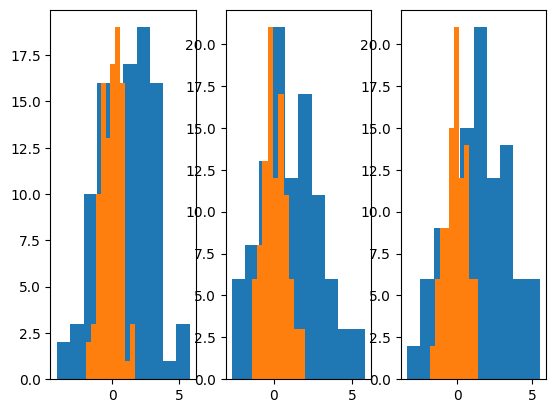

In [12]:
from matplotlib import pyplot as plt
import scipy
import scipy.stats
import torch
import numpy as np

n=3
scale=2
offset=1
tmp = torch.randn((10,n,10))*scale + offset

plt.Figure()
for i in np.arange(n):
    plt.subplot(1,n,i+1)
    plt.hist(tmp[:,i,:].flatten(), bins=10)


for i in np.arange(n):
    mu = torch.median(tmp[:,i,:])
    iqr = scipy.stats.iqr(tmp[:,i,:])
    tmp[:,i,:] = (tmp[:,i,:]-mu)/iqr

for i in np.arange(n):
    plt.subplot(1,n,i+1)
    plt.hist(tmp[:,i,:].flatten(), bins=10)


In [53]:
import pickle
with open(os.path.join(proj_dir, 'data', f'subdataset_{n_samples}.pkl'), 'wb') as f:
    pickle.dump(subdataset, f)

# Run inference

In [9]:
from torch.utils.data import Dataset, DataLoader, random_split
import torch
import torch.nn as nn
from transformers import get_cosine_schedule_with_warmup
from sklearn.metrics import r2_score
import numpy as np
import matplotlib.pyplot as plt

BATCH_SIZE = 16


## load your data using either 1 or 2:

# 1)
# data_tensors = torch.load("")
# fmri_data = data_tensors['fmri_data']
# fc_data = data_tensors['fc_data']
# G_tensor = data_tensors['G_tensor']


# 2)
# fmri_data = .....
# fc_data = compute_fc_fast(fmri_data)
# G_tensor = torch.randn(fmri_data.shape[0], 450, 10)


#dataset.fmri_data = dataset.fmri_data.reshape(-1,450,200)
#dataset.fc_data = dataset.fc_data.reshape(-1,450,450)
#dataset.G_tensor = torch.randn(dataset.fmri_data.shape[0], 450, 10)


# shuffled_indices = torch.randperm(fmri_data.size(0))
# fmri_data = fmri_data[shuffled_indices]
# fc_data = fc_data[shuffled_indices]
# G_tensor = G_tensor[shuffled_indices]



#dataset = FMRIDataset(fmri_data, fc_data, G_tensor)
data_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle = False)





# === Load pretrained models ===

DIM = 128
NUM_LAYERS = 6
NUM_HEADS = 4
MLP_DIM = 512
TIME_STEPS = 200
MAX_LEN_TEMP = 5000
TIME_STEPS = 200
MAX_LEN_SPATIAL = 500
NUM_GRADIENTS = 10
DELTA = 0.5
LEARNING_RATE = 1e-4
ROIs = 450



base_transformer = TemporalTransformer(NUM_LAYERS, DIM, NUM_HEADS, MLP_DIM, TIME_STEPS, MAX_LEN_TEMP).to(device)
masker = TokenMasker1D(mask_ratio=0)
temporal_model = MaskedTemporalTransformer(base_transformer, masker, roi_dim = 450, hidden_dim=256).to(device)


base_transformer = SpatialTransformer(
    num_layers=NUM_LAYERS,
    dim=DIM,
    num_heads=NUM_HEADS,
    mlp_dim=MLP_DIM,
    time_steps=TIME_STEPS,
    max_len=MAX_LEN_SPATIAL,
    num_gradients=NUM_GRADIENTS,
    delta=DELTA,
    pos_enc_type="learnable"
).to(device)
masker = TokenMasker2D(mask_ratio=0)
spatial_model = MaskedSpatialTransformer(base_transformer, masker, TIME_STEPS,  hidden_dim=256).to(device)


masker = TimePointMasker(mask_ratio=0)
conv_model = MaskedConv1DTemporalModel(input_channels=1, signal_dim=64, decoder_hidden_dims=[32, 8]).to(device)


temporal_model.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"temporal_transformer_pretrained_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))
spatial_model.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"spatial_transformer_pretrained_learnablePE_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))
conv_model.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"masked_conv1d_temporal_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))


perceiver = PerceiverIOModelROIWise(input_dim=64*3, latent_dim=128, num_rois=450, num_heads=2, time_steps=200, dropout=0.0).to(device)


perceiver.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"perceiver_fused_pretrained_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))



temporal_model.eval()
spatial_model.eval()
conv_model.eval()
perceiver.eval()


perciever_attn = []
all_spatial_attn_first = []
all_temporal_attn_first = []
all_temporal_attn_last = []
all_spatial_attn_last = []
all_recon_temp = []
all_recon_spat = []
all_recon_percv = []
all_roi_embeddings = []
for fmri, fc, gm in data_loader:
    fmri = fmri.to(device)
    fc = fc.to(device)
    gm = gm.to(device)
    gm, fmri, fc = gm.float(), fmri.float(), fc.float()



    with torch.no_grad():
        _, recon_spat, _, spatial_attn, roi_embeds,  roi_pos = spatial_model(gm, fmri, fc)         # (B, R, D)
        _, recon_temp, mask_temp, temporal_attn, time_embeds, _ = temporal_model(fmri)       # (B, T, D)
        _, signal_context = conv_model(fmri, mask=None)            # (B, R, T, d_signal)
        recon_percv, latents, percv_attn = perceiver(roi_embeds, time_embeds, signal_context, roi_pos)

    

        
        all_spatial_attn_first.append(spatial_attn[0])
        all_spatial_attn_last.append(spatial_attn[-1])
        all_temporal_attn_first.append(temporal_attn[0])
        all_temporal_attn_last.append(temporal_attn[-1])
        perciever_attn.append(percv_attn[-1])
        all_recon_temp.append(recon_temp)
        all_recon_spat.append(recon_spat)
        all_recon_percv.append(recon_percv)
        all_roi_embeddings.append(latents)
        
        


2025-12-24 04:34:21.206878: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-12-24 04:34:22.029980: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory
2025-12-24 04:34:22.030074: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory
2025-12-24 04:34:22.030084: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Cannot dlopen some TensorRT libraries. If you would like t

In [10]:
all_recon_temp = torch.cat(all_recon_temp, dim=0).cpu()
all_recon_spat = torch.cat(all_recon_spat, dim=0).cpu()
all_recon_percv = torch.cat(all_recon_percv, dim=0).cpu()
all_roi_embeddings = torch.cat(all_roi_embeddings, dim=0).cpu()
all_perceiver_attn = torch.cat(perciever_attn, dim=0).cpu()

In [12]:
percv_attn[0].shape

torch.Size([8, 2, 450, 450])

In [272]:
dataset.fmri_data.shape

torch.Size([392, 450, 200])

In [273]:
all_recon_spat.shape

torch.Size([392, 450, 200])

In [274]:
all_recon_temp.shape

torch.Size([392, 450, 200])

In [275]:
all_recon_percv.shape

torch.Size([392, 450, 200])

In [276]:
signal_context.shape

torch.Size([8, 450, 200, 64])

In [277]:
all_roi_embeddings.shape

torch.Size([392, 450, 128])

In [311]:
roi_pos.shape

torch.Size([3, 450, 128])

In [20]:
from matplotlib import pyplot as plt

## Filtered signal

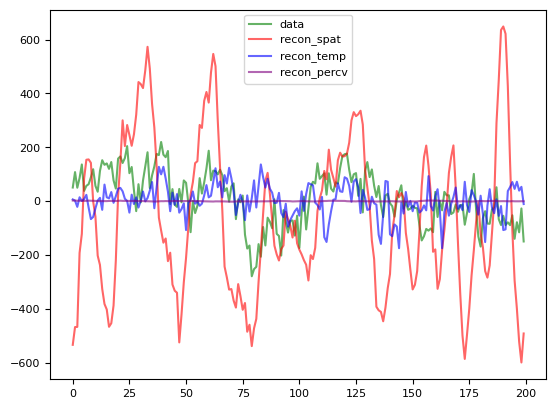

In [111]:
smpl = 8
roi = 250
lat = 0
data, spat, temp, percv = dataset.fmri_data[smpl,roi,:], all_recon_spat[smpl,roi,:], all_recon_temp[smpl,roi,:], all_recon_percv[smpl,roi,:]

plt.plot(data, color='green', label='data', alpha=0.6)
plt.plot(spat, color='red', label='recon_spat' , alpha=0.6)
plt.plot(temp, color='blue', label='recon_temp', alpha=0.6)
plt.plot(percv, color='purple', label='recon_percv', alpha=0.6)
plt.legend()

In [41]:
np.corrcoef([data, spat, temp, percv])

array([[1.        , 0.28238332, 0.43688796, 0.33088488],
       [0.28238332, 1.        , 0.07275093, 0.07446232],
       [0.43688796, 0.07275093, 1.        , 0.17216964],
       [0.33088488, 0.07446232, 0.17216964, 1.        ]])

## Unfiltered signal

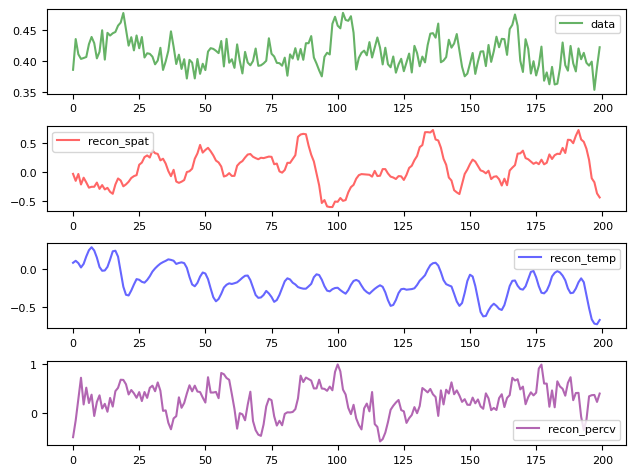

In [37]:
smpl = 20
roi = 100
data, spat, temp, percv = dataset.fmri_data[smpl,roi,:], all_recon_spat[smpl,roi,:], all_recon_temp[smpl,roi,:], all_recon_percv[smpl,roi,:]


plt.rcParams.update({'font.size':8})
plt.subplot(4,1,1)
plt.plot(data, color='green', label='data', alpha=0.6)
plt.legend()

plt.subplot(4,1,2)
plt.plot(spat, color='red', label='recon_spat' , alpha=0.6)
plt.legend()

plt.subplot(4,1,3)
plt.plot(temp, color='blue', label='recon_temp', alpha=0.6)
plt.legend()

plt.subplot(4,1,4)
plt.plot(percv, color='purple', label='recon_percv', alpha=0.6)
plt.legend()

plt.tight_layout()

In [38]:
np.corrcoef([data, spat, temp, percv])

array([[ 1.        , -0.26447176,  0.08614755,  0.15304089],
       [-0.26447176,  1.        ,  0.10256934,  0.02119087],
       [ 0.08614755,  0.10256934,  1.        ,  0.00614032],
       [ 0.15304089,  0.02119087,  0.00614032,  1.        ]])

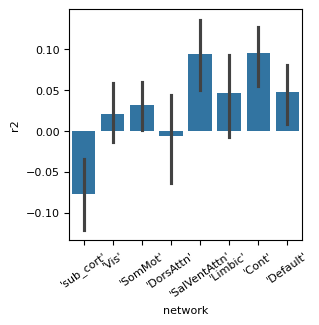

In [39]:
r2 = np.zeros((450,))
for i in range(450):
    r2[i] = sklearn.metrics.r2_score(dataset.fmri_data[:,i,:], all_recon_percv[:,i,:])


tmp = pd.DataFrame({'r2':r2, 'network':rs_nets})
plt.figure(figsize=(3,3))
ax = sbn.barplot(data=tmp, x='network', y='r2')
plt.xticks(rotation=35);

## HCP data

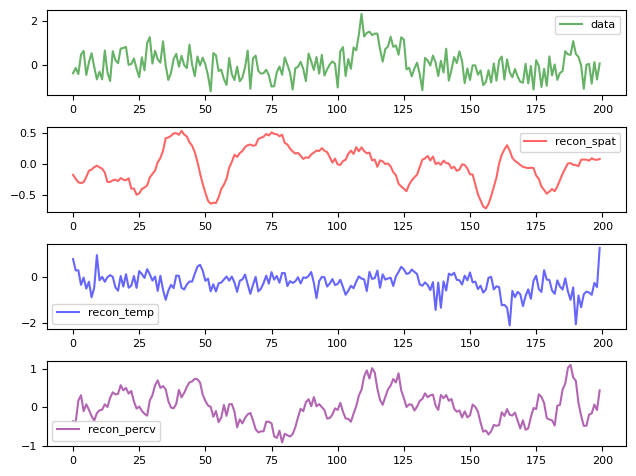

In [11]:
smpl = 14
roi = 60
data, spat, temp, percv = dataset.fmri_data[smpl,roi,:], all_recon_spat[smpl,roi,:], all_recon_temp[smpl,roi,:], all_recon_percv[smpl,roi,:]


plt.rcParams.update({'font.size':8})
plt.subplot(4,1,1)
plt.plot(data, color='green', label='data', alpha=0.6)
plt.legend()

plt.subplot(4,1,2)
plt.plot(spat, color='red', label='recon_spat' , alpha=0.6)
plt.legend()

plt.subplot(4,1,3)
plt.plot(temp, color='blue', label='recon_temp', alpha=0.6)
plt.legend()

plt.subplot(4,1,4)
plt.plot(percv, color='purple', label='recon_percv', alpha=0.6)
plt.legend()

plt.tight_layout()

In [12]:
np.corrcoef([data, spat, temp, percv])

array([[ 1.        ,  0.06135295,  0.09750624,  0.52674108],
       [ 0.06135295,  1.        , -0.12166517, -0.03756112],
       [ 0.09750624, -0.12166517,  1.        ,  0.09414453],
       [ 0.52674108, -0.03756112,  0.09414453,  1.        ]])

<BarContainer object of 450 artists>

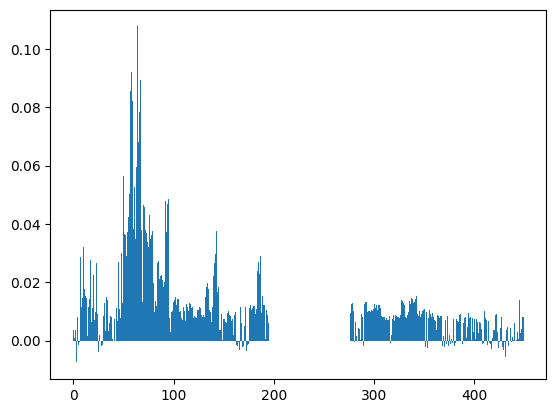

In [23]:
r2 = np.zeros((450,))
for i in range(450):
    r2[i] = sklearn.metrics.r2_score(dataset.fmri_data[:,i,:], all_recon_percv[:,i,:])
plt.bar(x=np.arange(450), height=r2)

In [21]:
import pandas as pd
rs_nets = pd.read_csv(os.path.join(proj_dir, 'parcellations', 'networks.txt'), header=None, sep=',')
rs_nets = rs_nets[0]
rs = rs_nets.unique()
rs = [s[1:-1] for s in rs]

In [22]:
net_colors = ['red', 'green', 'purple', 'blue', 'brown', 'yellow', 'magenta']
rs_colors = {name:col for name,col in zip(rs,net_colors)}
rs_colors

{'sub_cort': 'red',
 'Vis': 'green',
 'SomMot': 'purple',
 'DorsAttn': 'blue',
 'SalVentAttn': 'brown',
 'Limbic': 'yellow',
 'Cont': 'magenta'}

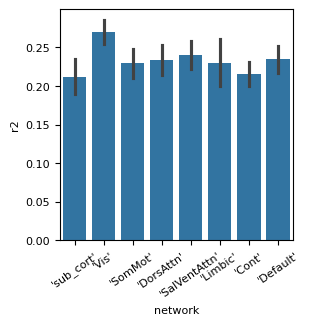

In [33]:
tmp = pd.DataFrame({'r2':r2, 'network':rs_nets})

plt.figure(figsize=(3,3))
ax = sbn.barplot(data=tmp, x='network', y='r2')

plt.xticks(rotation=35);

In [26]:
help(sbn.barplot)

Help on function barplot in module seaborn.categorical:

barplot(data=None, *, x=None, y=None, hue=None, order=None, hue_order=None, estimator='mean', errorbar=('ci', 95), n_boot=1000, seed=None, units=None, weights=None, orient=None, color=None, palette=None, saturation=0.75, fill=True, hue_norm=None, width=0.8, dodge='auto', gap=0, log_scale=None, native_scale=False, formatter=None, legend='auto', capsize=0, err_kws=None, ci=<deprecated>, errcolor=<deprecated>, errwidth=<deprecated>, ax=None, **kwargs)
    Show point estimates and errors as rectangular bars.
    
    A bar plot represents an aggregate or statistical estimate for a numeric
    variable with the height of each rectangle and indicates the uncertainty
    around that estimate using an error bar. Bar plots include 0 in the
    axis range, and they are a good choice when 0 is a meaningful value
    for the variable to take.
    
    See the :ref:`tutorial <categorical_tutorial>` for more information.
    
    .. note::
   

## OCD dataset -- fmriprep only

In [24]:
importlib.reload(OCD_symphony.data_validation.validate_preprocessing)
importlib.reload(OCD_symphony.data_validation)
importlib.reload(OCD_symphony)


<module 'OCD_symphony' from '/home/sebastin/working/lab_lucac/sebastiN/projects/OCD_Symphony/src/OCD_symphony/__init__.py'>

### OCD + HC (mixed)

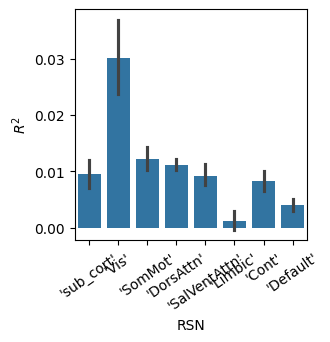

In [27]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### HC only

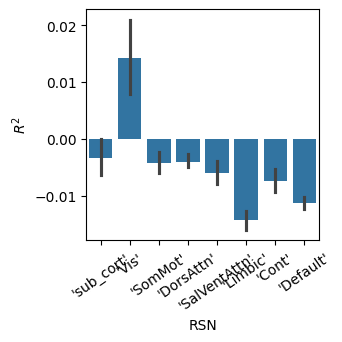

In [25]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### OCD only

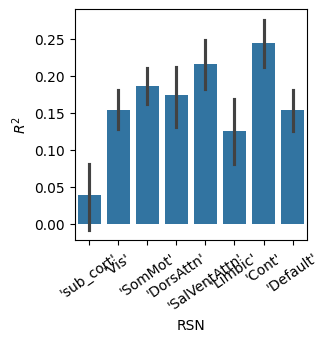

In [38]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### OCD + HC (OCDbaseline)

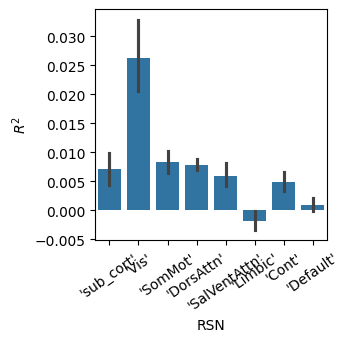

In [21]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### HC only (OCDbaseline)

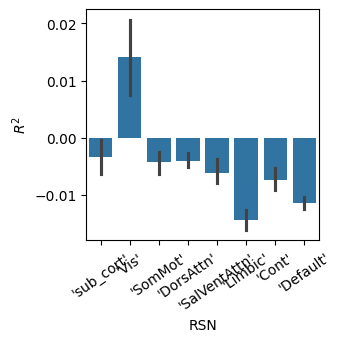

In [34]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### OCD only (OCDbaseline)

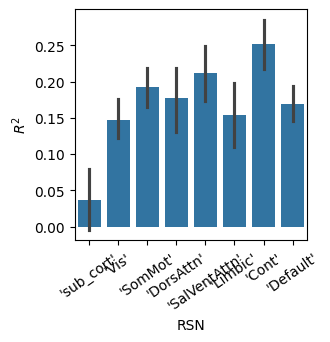

In [47]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

## HCP - 10 subjs recon stats

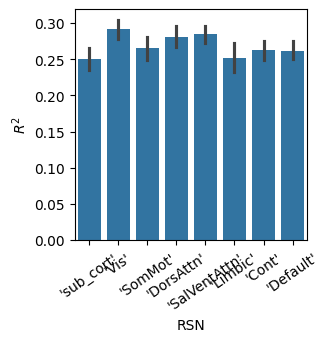

In [21]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

## OCD dataset fmriprep-fix (mixed)

### HC only

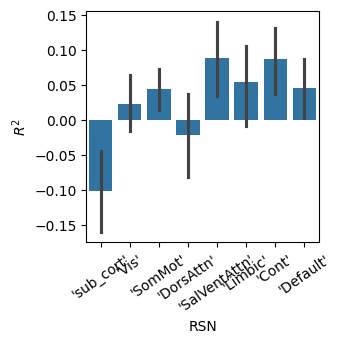

In [59]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### OCD only

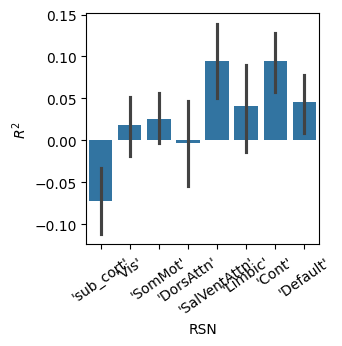

In [72]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

## fmriprep backup res-2

### HC only

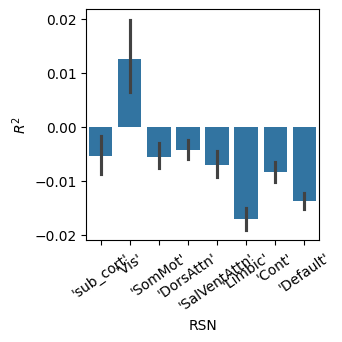

In [48]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### OCD only

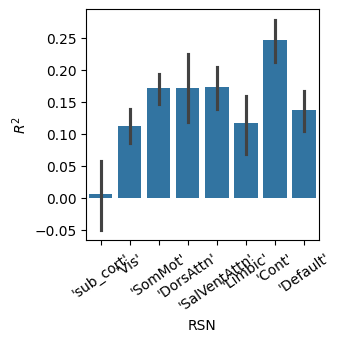

In [96]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### HC + OCD    

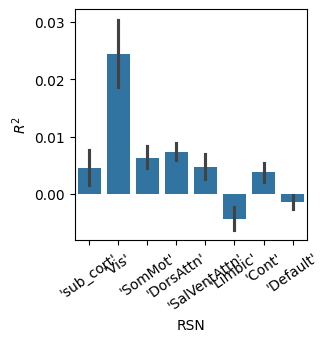

In [108]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

### HC + OCD after z-scoring

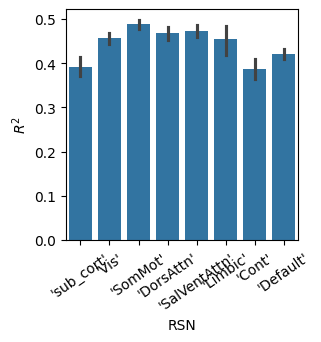

In [279]:
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()
r2 = OCD_symphony.data_validation.compute_r2(dataset.fmri_data, all_recon_percv)
OCD_symphony.data_validation.plot_recon_barplot(r2, rs_nets)

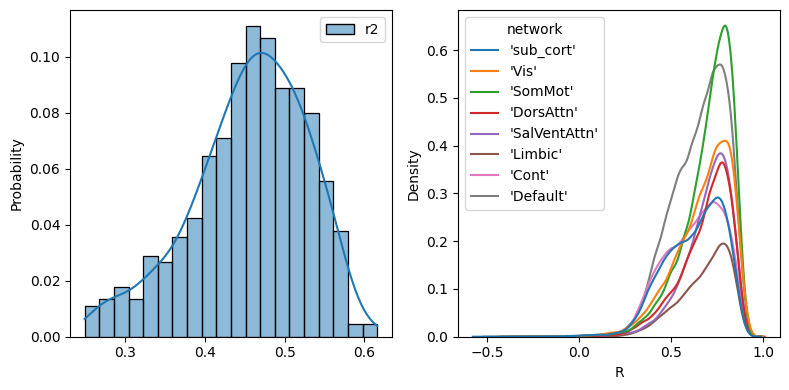

In [11]:
# create labels
labels = np.array([0 if 'control' in s else 1 for s in subjs])

# get RSNs correpsondign to ROIs 
rs_nets, rs = OCD_symphony.data_validation.load_RSNs()

# HC reconstruction 
# ------------------ 
hc_inds, = np.where(labels==0)
r2_hc = OCD_symphony.data_validation.compute_r2(dataset.fmri_data[hc_inds], all_recon_percv[hc_inds])

# Overall
plt.figure(figsize=[8,4])
ax1 = plt.subplot(1,2,1)
sbn.histplot(pd.DataFrame({'r2':r2_hc}), bins=20, kde=True, stat='probability', ax=ax1)

# Subject specific
subjs_recon = []
for subj in np.unique(subjs):
    subj_inds, = np.where(subjs==subj)
    #r2_subj = OCD_symphony.data_validation.compute_r2(dataset.fmri_data[subj_inds,:,:], all_recon_percv[subj_inds,:,:])
    for sample_idx in subj_inds:
        for roi_idx in np.arange(dataset.fmri_data.shape[1]):
            R = np.corrcoef(dataset.fmri_data[sample_idx,roi_idx,:], all_recon_percv[sample_idx,roi_idx,:])[0,1]
            subj_recon = {'R':R, 'subj':subj, 'network': rs_nets[roi_idx]}
            subjs_recon.append(subj_recon)

df_subjs_recon = pd.DataFrame(subjs_recon)
ax2 = plt.subplot(1,2,2)
sbn.kdeplot(data=df_subjs_recon, x='R', hue='network', ax=ax2)
plt.tight_layout()

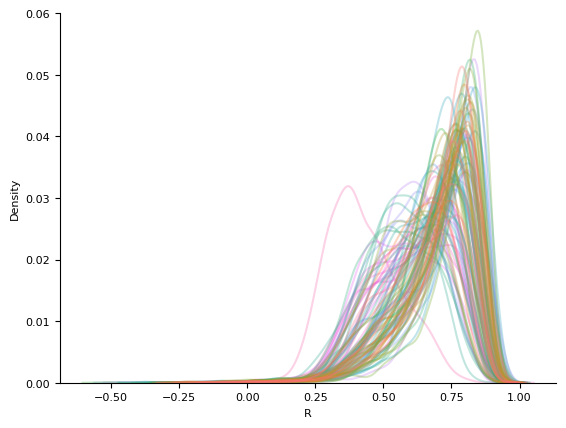

In [423]:
ax = sbn.kdeplot(data=df_subjs_recon, x='R', hue='subj', legend=False, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

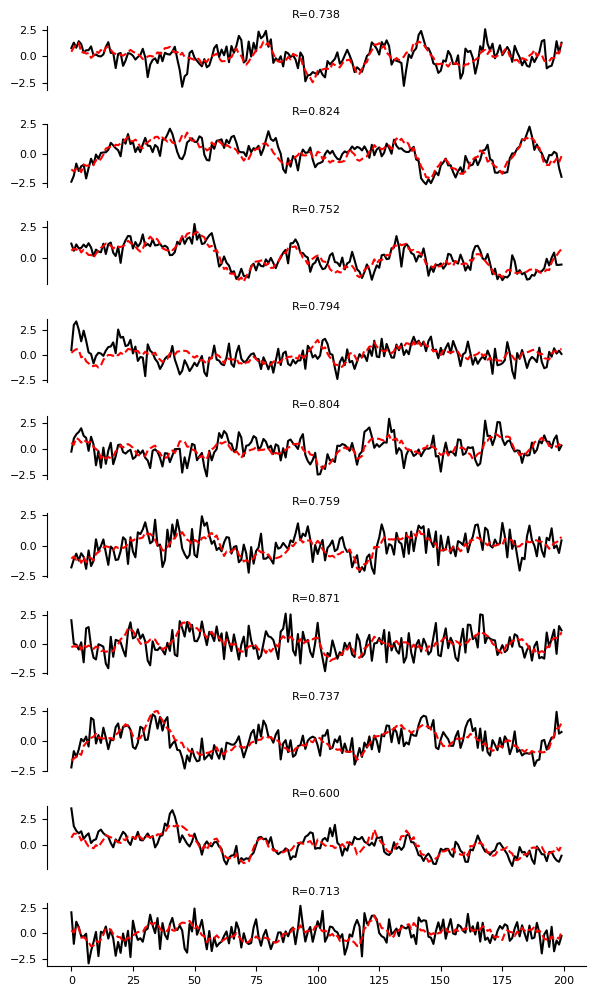

In [400]:
ori = dataset.fmri_data[subj_inds,:,:]
rec = all_recon_percv[subj_inds,:,:]

sampl = 2
nrois = 10

plt.rcParams.update({'font.size':8})

plt.figure(figsize=[6,10])
for i, idx in enumerate(np.random.randint(0,450,nrois)):
    ax = plt.subplot(nrois, 1, i+1)
    plt.plot(ori[sampl,idx,:], color='k', label='original')
    plt.plot(rec[sampl,idx,:], '--', color='r', label='reconstructed')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if i != (nrois-1):
        ax.spines['bottom'].set_visible(False)
        ax.set_xticks([])
    plt.title(f"R={np.corrcoef(ori[sampl,i,:], rec[sampl,i,:])[0,1]:.3f}", fontsize=8)
plt.tight_layout()

# Predictive analysis

In [11]:
import argparse
importlib.reload(OCD_symphony.predictive_analysis.ocd_hc_classification)
importlib.reload(OCD_symphony.predictive_analysis)

<module 'OCD_symphony.predictive_analysis' from '/home/sebastin/working/lab_lucac/sebastiN/projects/OCD_Symphony/src/OCD_symphony/predictive_analysis/__init__.py'>

In [12]:
#clf = sklearn.linear_model.RidgeClassifier()
clf = sklearn.svm.SVC(gamma='auto')
args = {'n_splits':5}
args = argparse.Namespace(**args)

# flatten recon_percv (latent * roi)
X = all_roi_embeddings.reshape(-1, all_roi_embeddings.shape[-2]*all_roi_embeddings.shape[-1])

# create labels
y = np.array([0 if 'control' in s else 1 for s in subjs]) #((all_recon_percv.shape[0]))

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)

clf_out = OCD_symphony.predictive_analysis.classify(clf, X, y, groups, args)
clf_out['scores']


[0.425, 0.4125, 0.55, 0.5921052631578947, 0.5526315789473685]

In [45]:
sklearn.model_selection.cross_val_score(clf, X, y=y, groups=subjs)

array([0.58227848, 0.44303797, 0.5       , 0.52564103, 0.61538462])

In [24]:
all_roi_embeddings.shape

torch.Size([392, 450, 128])

## Moein's original

In [158]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, StratifiedGroupKFold, GroupShuffleSplit, cross_validate
from sklearn.metrics import accuracy_score, roc_auc_score

X = all_roi_embeddings   ## shape (32,450,128)

# Labels: first 16 control (0), next 16 OCD (1)
#y = np.array([0]*16 + [1]*16)
y = np.array([0 if 'control' in s else 1 for s in subjs])

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)


# use a a small subset of the dataset
n_samples = 16
hc_inds = np.random.permutation(np.where(~y.astype(bool))[0])[:n_samples]
ocd_inds = np.random.permutation(np.where(y.astype(bool))[0])[:n_samples]
inds = np.concatenate([hc_inds, ocd_inds])
X = X[inds,:,:]
y = y[inds]
groups = groups[inds]

# 1) Pool ROIs to get one 128-d vector per subject
X_pooled = X.mean(axis=1)            # shape: (32, 128)

# 2) Pipeline: scale -> elastic-net logistic regression
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=10000,
        l1_ratio=0.5,        # tuned via grid below
        C=1.0,               # tuned via grid below
    ))
])

# 3) Hyperparam search with nested CV (small grid to keep it stable)
param_grid = {
    "clf__C": [0.1, 0.3, 1.0, 3.0, 10.0],
    "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}
inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
outer = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)

search = GridSearchCV(pipe, param_grid, cv=inner, scoring="accuracy", n_jobs=32, verbose=1)
scores = cross_val_score(search, X_pooled, y, cv=outer, scoring="accuracy")
print(f"Accuracy (outer CV): mean={scores.mean():.3f} ± {scores.std():.3f}")

# Optional: traithe n final model to inspect coefficients
search.fit(X_pooled, y)
final_model = search.best_estimator_
print("Best params:", search.best_params_)



Fitting 4 folds for each of 25 candidates, totalling 100 fits
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Accuracy (outer CV): mean=0.656 ± 0.214
Fitting 4 folds for each of 25 candidates, totalling 100 fits
Best params: {'clf__C': 0.1, 'clf__l1_ratio': 0.7}


In [159]:
from sklearn.model_selection import permutation_test_score
score, perm, pval = permutation_test_score(
    search.best_estimator_, X_pooled, y,
    cv=outer, scoring="accuracy", n_permutations=100, random_state=0, n_jobs=32)
print("Permutation p-value:", pval)

Permutation p-value: 0.009900990099009901


# Create new labels for different demographic measure

In [11]:
df_behavs = pd.read_csv(os.path.join(proj_dir, 'data', 'demographics.csv'))

emb_data = {}

# Cohort
labels = np.array([0 if 'control' in s else 1 for s in subjs])
emb_data['labels'] = torch.from_numpy(labels)

# Age
behav = 'Age'
y = []
y.append([df_behavs[df_behavs.subj==subj][behav].values[0] for subj in subjs])
y = torch.Tensor(y).reshape(-1,)
emb_data['ages'] = y


# Gender
behav = 'Gender'
y = []
y.append([df_behavs[df_behavs.subj==subj][behav].values[0] for subj in subjs])
y = np.array(y).reshape(-1,)
le = sklearn.preprocessing.LabelEncoder()
le.fit(y)
y = le.transform(y)
y = torch.Tensor(y).reshape(-1,)
emb_data['genders'] = y


# YBOCS
behav = 'YBOCS_Total'
y = []
y.append([df_behavs[df_behavs.subj==subj][behav].values[0] for subj in subjs])
y = torch.Tensor(y).reshape(-1,)
emb_data['YBOCS'] = y

In [284]:
emb_data

{'embeddings': tensor([[[ 8.4684e-01,  9.4335e-01,  4.8006e-01,  ...,  3.0277e+00,
            6.1529e-01, -6.8780e-01],
          [ 1.5471e+00,  1.8005e+00, -1.8206e+00,  ...,  2.0910e+00,
            5.8123e-01, -1.2685e+00],
          [ 8.9230e-02,  1.6647e+00, -1.3232e+00,  ..., -6.1261e-01,
            1.3164e+00, -3.5318e-01],
          ...,
          [ 1.2803e+00,  5.6807e-01, -1.5053e+00,  ...,  4.1085e-02,
           -1.3064e-01,  5.7913e-01],
          [-3.6098e-02,  1.6818e+00, -1.7290e-01,  ...,  8.2240e-01,
           -6.6387e-01,  6.7799e-01],
          [ 9.0390e-01,  4.5175e-01,  3.9955e-01,  ...,  1.0855e+00,
            1.0623e-01, -5.4419e-01]],
 
         [[ 7.6157e-02,  9.7008e-01, -8.2531e-01,  ...,  1.9388e+00,
            5.0404e-01, -1.9675e+00],
          [ 1.2401e+00,  8.2751e-01, -1.8891e-01,  ...,  1.4761e+00,
            5.5106e-01, -5.9989e-01],
          [ 1.0534e+00,  1.5461e+00, -2.0936e+00,  ...,  9.9074e-01,
            1.0212e+00, -5.8949e-01],
     

In [285]:
#with open(os.path.join(proj_dir, 'data', 'OCDbaseline_fmriprep_MNI152NLin2009cAsym_res-2', 'subjects_embeddings_and_demographics.pkl'), 'wb') as f:
#    pickle.dump(emb_data, f)

## StratifiedGroupKFold

In [286]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, StratifiedGroupKFold, GroupShuffleSplit, cross_validate
from sklearn.metrics import accuracy_score, roc_auc_score

X = all_roi_embeddings   ## shape (32,450,128)

# Labels: first 16 control (0), next 16 OCD (1)
#y = np.array([0]*16 + [1]*16)
y = np.array([0 if 'control' in s else 1 for s in subjs])
y = emb_data['genders']

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)

# use a a small subset of the dataset
#n_samples = 16
#hc_inds = np.random.permutation(np.where(~y.astype(bool))[0])#[:n_samples]
#ocd_inds = np.random.permutation(np.where(y.astype(bool))[0])#[:n_samples]
#inds = np.concatenate([hc_inds, ocd_inds])
#X = X[inds,:,:]
#y = y[inds]
#groups = groups[inds]

# 1) Pool ROIs to get one 128-d vector per subject
X_pooled = X.mean(axis=1)            # shape: (32, 128)
#X_flattened = X.reshape(X.shape[0], X.shape[1]*X.shape[2]) 

# 2) Pipeline: scale -> elastic-net logistic regression
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=10000,
        l1_ratio=0.5,        # tuned via grid below
        C=1.0,               # tuned via grid below
    ))
])

# 3) Hyperparam search with nested CV (small grid to keep it stable)
param_grid = {
    "clf__C": [0.1, 0.3, 1.0, 3.0, 10.0],
    "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0)

search = GridSearchCV(pipe, param_grid, cv=list(inner.split(X_pooled, y, groups)), scoring="accuracy", n_jobs=32, verbose=1)
search.fit(X_pooled, y, groups=groups)

print(f"Best params: {search.best_params_}")

outer = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)
scores = sklearn.model_selection.cross_validate(search.best_estimator_, X_pooled, y, groups=groups, cv=outer, n_jobs=32, verbose=0, return_train_score=True)

print(f"Training accuracy \t = \t {scores['train_score'].mean():.3f} ± {scores['train_score'].std():.3f}")
print(f"Test accuracy \t\t = \t {scores['test_score'].mean():.3f} ± {scores['test_score'].std():.3f}")

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best params: {'clf__C': 10.0, 'clf__l1_ratio': 0.7}
Training accuracy 	 = 	 0.977 ± 0.014
Test accuracy 		 = 	 0.477 ± 0.080


In [287]:
from sklearn.model_selection import permutation_test_score
score, perm, pval = permutation_test_score(
    search.best_estimator_, X_pooled, y, groups=groups,
    cv=outer, scoring="accuracy", n_permutations=100, random_state=0, n_jobs=32)
print("Permutation p-value:", pval)

Permutation p-value: 1.0


In [282]:
import pickle
emb_data = {'embeddings':X, 'labels':y, 'subjs':subjs}

# Fine-tuning

## OCD vs HC

In [294]:
dataset.emb_data['ages']

torch.Size([392])

In [307]:
from torch.utils.data import Dataset
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split 
from transformers import get_cosine_schedule_with_warmup
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

# === Device ===
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

"""
class FMRIDataset(Dataset):
    def __init__(self, fmri_data, fc_data, G_tensor, labels):
        self.fmri_data = fmri_data
        self.fc_data = fc_data
        self.G_tensor = G_tensor
        self.labels = labels # shape: (N,) or (N, 1)

    def __getitem__(self, idx):
        return self.fmri_data[idx], self.fc_data[idx], self.G_tensor[idx], self.labels[idx]

    def __len__(self):
        return len(self.fmri_data)
"""

# === Parameters ===
BATCH_SIZE = 4
NUM_EPOCHS = 300
DIM = 128
NUM_LAYERS = 6
NUM_HEADS = 4
MLP_DIM = 512
TIME_STEPS = 200
MAX_LEN_SPATIAL = 500
NUM_GRADIENTS = 10
DELTA = 0.5
LEARNING_RATE = 1e-4
MAX_LEN_TEMP = 5000
POPULATION_SIZE, ROIs, TIME_STEPS = dataset.fmri_data.shape

# === Load data ===
"""
data_tensors = torch.load("/home/mkha0111/dn68/Moein_HCP_aging/data/all_tensors_age_200.pt")
fmri_data = data_tensors['fmri_data']
fc_data = data_tensors['fc_data']
G_tensor = data_tensors['G_tensor']


shuffled_indices = torch.randperm(fmri_data.size(0))
fmri_data = fmri_data[shuffled_indices]
fc_data = fc_data[shuffled_indices]
G_tensor = G_tensor[shuffled_indices]
subjects_Gender = torch.tensor(repeated_subjects_age_Gender[:int(len(final_time_series_age_tensor)* 0.8)],dtype=torch.long)[shuffled_indices]
dataset = FMRIDataset(fmri_data,fc_data, G_tensor, subjects_Gender)
"""
dataset.labels = emb_data['labels']

# shuffle samples
shuffled_indices = torch.randperm(dataset.fmri_data.shape[0])
dataset.fmri_data = dataset.fmri_data[shuffled_indices]
dataset.fc_data = dataset.fc_data[shuffled_indices]
dataset.G_tensor = dataset.G_tensor[shuffled_indices]
dataset.labels = dataset.labels[shuffled_indices]

train_data, val_data = random_split(dataset, [int(0.8* len(dataset)), len(dataset) - int(0.8* len(dataset))])
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE,shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE)


# === Load pretrained models ===
base_transformer = TemporalTransformer(NUM_LAYERS,DIM, NUM_HEADS, MLP_DIM, TIME_STEPS, MAX_LEN_TEMP).to(device)
masker = TokenMasker1D(mask_ratio=0)
temporal_model = MaskedTemporalTransformer(base_transformer,masker, roi_dim = 450, hidden_dim=256).to(device)
base_transformer = SpatialTransformer(num_layers=NUM_LAYERS,
                                      dim=DIM,
                                      num_heads=NUM_HEADS,
                                      mlp_dim=MLP_DIM,
                                      time_steps=TIME_STEPS,
                                      max_len=MAX_LEN_SPATIAL,
                                      num_gradients=NUM_GRADIENTS,
                                      delta=DELTA,
                                      pos_enc_type="learnable").to(device)

masker = TokenMasker2D(mask_ratio=0)
spatial_model = MaskedSpatialTransformer(base_transformer,masker, TIME_STEPS, hidden_dim=256).to(device)

masker = TimePointMasker(mask_ratio=0)
conv_model = MaskedConv1DTemporalModel(input_channels=1,signal_dim=64,decoder_hidden_dims=[32,8]).to(device)

#temporal_model.load_state_dict(torch.load(f"./Pretrained_models/temporal_transformer_pretrained_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth"))
#spatial_model.load_state_dict(torch.load(f"./Pretrained_models/spatial_transformer_pretrained_learnablePE_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth"))
#conv_model.load_state_dict(torch.load(f"./Pretrained_models/masked_conv1d_temporal_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth"))
temporal_model.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"temporal_transformer_pretrained_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))
spatial_model.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"spatial_transformer_pretrained_learnablePE_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))
conv_model.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"masked_conv1d_temporal_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))

temporal_model.eval()
spatial_model.eval()
conv_model.eval()

# make sure the encoders are not re-trained
for model in [spatial_model,temporal_model, conv_model]:
    for param in model.parameters():
        param.requires_grad = False

# === Load Pretrained Perceiver ===
#perceiver = PerceiverIOModelROIWise(input_dim=64*3, latent_dim=128, num_rois=450, num_heads=NUM_HEADS, time_steps=TIME_STEPS).to(device)
#perceiver.load_state_dict(torch.load(f"./Pretrained_models/perceiver_fused_pretrained_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth"))
perceiver = PerceiverIOModelROIWise(input_dim=64*3, latent_dim=128, num_rois=450, num_heads=NUM_HEADS, time_steps=TIME_STEPS, dropout=0.0).to(device)
perceiver.load_state_dict(torch.load(os.path.join(proj_dir, 'models', f"perceiver_fused_pretrained_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth")))

classifier = PerceiverClassifier(perceiver, latent_dim=128, num_classes=2).to(device)

# make sure the classfier is trained
print("Trained parameters of the classifier:")
for name, param in classifier.named_parameters():
    print(name, param.requires_grad)


# === Optimizer and Loss ===
optimizer = torch.optim.AdamW(classifier.parameters(),
                              lr=LEARNING_RATE,
                              weight_decay=1e-2)
scheduler = get_cosine_schedule_with_warmup(optimizer, 
                                            0.1 * NUM_EPOCHS * len(train_loader), 
                                            NUM_EPOCHS * len(train_loader))
criterion = nn.CrossEntropyLoss()

# === Training Loop ===
best_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    classifier.train()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []

    for fmri, fc, gm, labels in train_loader:
        fmri, fc, gm, labels = fmri.to(device), fc.to(device), gm.to(device), labels.to(device)
        # fmri_norm = (fmri - fmri.mean(dim=-1, keepdim=True)) / (fmri.std(dim=-1, keepdim=True) + 1e-8)

        with torch.no_grad():
            _, _, _, _, roi_embeds, roi_pos = spatial_model(gm, fmri, fc)
            _, _, _, _, time_embeds, _ = temporal_model(fmri)
            _, signal_context = conv_model(fmri, mask=None)

        logits, recon = classifier(roi_embeds, time_embeds, signal_context, roi_pos)

        loss = criterion(logits,labels) + F.mse_loss(recon, fmri)
        #loss.requires_grad = True # <- this was added by Seb

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    train_acc = correct / total
    train_f1 = f1_score(all_labels, all_preds, average='macro')

    print(f"[Epoch{epoch+1}] Train Loss: {total_loss:.4f} | Acc:{train_acc:.4f} | F1:{train_f1:.4f}")

    # === Validation ===
    classifier.eval()
    val_correct, val_total = 0, 0
    val_preds, val_labels_list = [], []

    with torch.no_grad():
        for fmri, fc, gm, labels in val_loader:
            fmri, fc, gm, labels = fmri.to(device), fc.to(device), gm.to(device), labels.to(device)
            # fmri_norm = (fmri - fmri.mean(dim=-1, keepdim=True)) / (fmri.std(dim=-1, keepdim=True) + 1e-8)
            
            _, _, _, _, roi_embeds, roi_pos = spatial_model(gm, fmri, fc)
            _, _, _, _, time_embeds, _ = temporal_model(fmri)
            _, signal_context = conv_model(fmri, mask=None)

            logits, recon = classifier(roi_embeds, time_embeds, signal_context, roi_pos)
            preds = logits.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
            val_preds.extend(preds.cpu().tolist())
            val_labels_list.extend(labels.cpu().tolist())

        val_acc = val_correct / val_total
        val_f1 = f1_score(val_labels_list,val_preds, average='macro')

    print(f"[Epoch{epoch+1}] Val Acc: {val_acc:.4f} | Val F1:{val_f1:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc


torch.save(classifier.state_dict(),
            os.path.join(proj_dir, 'models', f"Fine_tuned_perceiver_classifier_gender_nL{NUM_LAYERS}_d{DIM}_h{NUM_HEADS}_mlp{MLP_DIM}.pth"))

print("✅ Fine-tuning Complete.")


[Epoch1] Train Loss: 119.6483 | Acc:0.5431 | F1:0.3520
[Epoch1] Val Acc: 0.5316 | Val F1:0.3471
[Epoch2] Train Loss: 114.2406 | Acc:0.5431 | F1:0.3520
[Epoch2] Val Acc: 0.5316 | Val F1:0.3471
[Epoch3] Train Loss: 111.3159 | Acc:0.5495 | F1:0.3672
[Epoch3] Val Acc: 0.4684 | Val F1:0.4578
[Epoch4] Train Loss: 110.2721 | Acc:0.5240 | F1:0.5135
[Epoch4] Val Acc: 0.5316 | Val F1:0.3471
[Epoch5] Train Loss: 107.3646 | Acc:0.5911 | F1:0.5346
[Epoch5] Val Acc: 0.4684 | Val F1:0.3190
[Epoch6] Train Loss: 105.0129 | Acc:0.6134 | F1:0.6024
[Epoch6] Val Acc: 0.5190 | Val F1:0.5010
[Epoch7] Train Loss: 99.4897 | Acc:0.7476 | F1:0.7380
[Epoch7] Val Acc: 0.5570 | Val F1:0.4823
[Epoch8] Train Loss: 92.3844 | Acc:0.7827 | F1:0.7747
[Epoch8] Val Acc: 0.5949 | Val F1:0.5319
[Epoch9] Train Loss: 83.8441 | Acc:0.8786 | F1:0.8763
[Epoch9] Val Acc: 0.4810 | Val F1:0.4688
[Epoch10] Train Loss: 73.9227 | Acc:0.9585 | F1:0.9580
[Epoch10] Val Acc: 0.5696 | Val F1:0.5611
[Epoch11] Train Loss: 64.0675 | Acc:0.9585

In [308]:
torch.__version__


'2.0.1+cu117'

In [444]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, classification_report
from sklearn.decomposition import PCA

inds = np.arange(0,392,4)

roi_embeddings = all_roi_embeddings[inds,:,:] #OCD_data['embeddings']
OCD_labels = np.array([0 if 'control' in s else 1 for s in subjs])[inds] #OCD_data['labels']
# OCD_labels = OCD_data['genders']

# Inputs:
# roi_embeddings: shape (392, 450, 128)
# OCD_labels: shape (392,), values {0,1}
# If it's a torch tensor, convert first: roi_embeddings = roi_embeddings.cpu().numpy()

# shuffled_indices = torch.randperm(roi_embeddings.size(0))
# roi_embeddings = roi_embeddings[shuffled_indices]
# OCD_labels = OCD_labels[shuffled_indices]

# 1) Subject-level features by pooling across ROIs
X_mean = roi_embeddings.mean(axis=2)             # (392, 128)
X_std  = roi_embeddings.std(axis=2, correction=1)      # (392, 128)
X = roi_embeddings.view(roi_embeddings.shape[0],-1) # torch.cat([X_mean, X_std], dim=1)      # (392, 256)

## For OCD classification
y = OCD_labels.astype(int)

## For Gender classification
# X = X.numpy()
# y = OCD_labels.numpy().astype(int)


# 2) Classifier (balanced logistic regression)
clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, class_weight="balanced", solver="lbfgs")
)

# clf = make_pipeline(
#     StandardScaler(),
#     PCA(n_components=20, random_state=42),
#     LogisticRegression(max_iter=5000, class_weight="balanced")
# )


# 3) Stratified 5-fold CV evaluation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_pred = cross_val_predict(clf, X, y, cv=cv)
acc = accuracy_score(y, y_pred)

# For ROC-AUC we need probabilities:
y_prob = cross_val_predict(clf, X, y, cv=cv, method="predict_proba")[:, 1]
auc = roc_auc_score(y, y_prob)
f1 = f1_score(y, y_pred)

print('OCD Classification:')
print(f"Accuracy: {acc:.3f} | ROC-AUC: {auc:.3f} | F1: {f1:.3f}")
print(classification_report(y, y_pred, digits=3))

OCD Classification:
Accuracy: 0.520 | ROC-AUC: 0.495 | F1: 0.591
              precision    recall  f1-score   support

           0      0.472     0.378     0.420        45
           1      0.548     0.642     0.591        53

    accuracy                          0.520        98
   macro avg      0.510     0.510     0.506        98
weighted avg      0.513     0.520     0.513        98



In [445]:
X.shape

torch.Size([98, 57600])

# Analysing attention heads

In [12]:
import json
import matplotlib
import nilearn
import nilearn.image
import nilearn.plotting
import numpy as np
import pickle
from time import time

In [13]:
all_perceiver_attn = torch.cat(perciever_attn, dim=0).cpu()
all_perceiver_attn.shape

torch.Size([392, 2, 450, 450])

In [73]:
hc_inds, = np.where(labels==0)
ocd_inds, = np.where(labels==1)

head=1

hc_attn = all_perceiver_attn[hc_inds, head, :, :].squeeze()
ocd_attn = all_perceiver_attn[ocd_inds, head, :, :].squeeze()

res = scipy.stats.ttest_ind(hc_attn, ocd_attn, axis=0, permutations=500, equal_var=False)
res

TtestResult(statistic=array([[ 2.6223037 ,  2.1355011 ,  2.5838575 , ...,  1.1564883 ,
        -0.6077225 , -0.515115  ],
       [ 2.3063865 ,  1.3375242 ,  1.0011189 , ..., -0.65838057,
        -0.65134495, -0.5780773 ],
       [ 2.7281137 ,  0.3214243 ,  2.103572  , ...,  1.1838255 ,
         1.2442122 , -0.66109836],
       ...,
       [ 1.0919498 , -0.12364075,  1.1052526 , ...,  0.52494377,
        -0.09343802, -0.9265191 ],
       [-0.47767076, -0.7487937 ,  1.5554168 , ...,  2.0824094 ,
         2.510645  , -1.3232715 ],
       [ 0.62390333,  0.25612587,  0.24652097, ...,  1.4511104 ,
         0.4012457 ,  1.1208079 ]], dtype=float32), pvalue=array([[0.00798403, 0.03592814, 0.00998004, ..., 0.25548902, 0.58483034,
        0.59081836],
       [0.01796407, 0.19361277, 0.30339321, ..., 0.52694611, 0.50499002,
        0.56686627],
       [0.00798403, 0.76447106, 0.03193613, ..., 0.23952096, 0.19560878,
        0.49101796],
       ...,
       [0.28143713, 0.92215569, 0.30538922, ...,

In [39]:
sig_inds = np.where(res[1]<0.05)

In [40]:
sig_inds[0].shape

(22742,)

In [43]:
R_Acc_shell_ind = 21
R_Acc_core_ind = 22

sig_inds, = np.where(res[1][R_Acc_shell_ind,:]<0.05)
len(sig_inds)

26

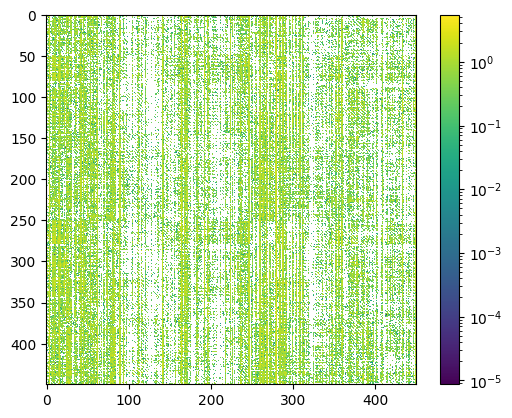

In [26]:
plt.imshow(res[0], norm='log')
plt.colorbar()

Text(0.5, 1.0, 'Attention weights (p<0.01)')

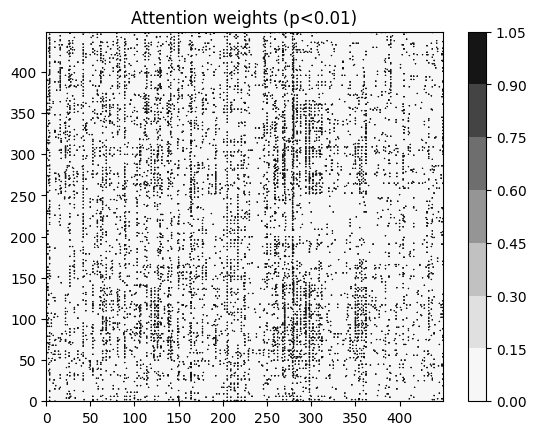

In [32]:
sigp = np.zeros((450,450))
row,col = np.where(res[1]<0.01)
sigp[row,col] = (1-res[1])[row,col]
plt.contourf(sigp, cmap='Grays')
plt.colorbar()
plt.title('Attention weights (p<0.01)')

Text(0.5, 1.0, 'T stat (p<0.01)')

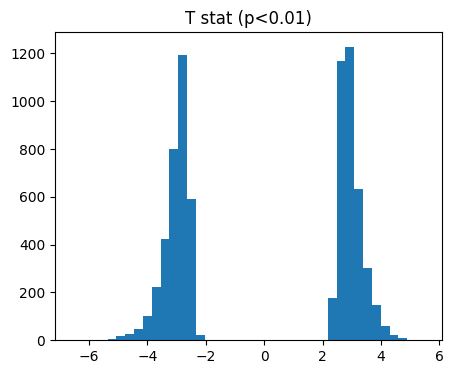

In [23]:
plt.figure(figsize=(5,4))
plt.hist(res[0][row,col], bins=40);
plt.title('T stat (p<0.01)')

In [33]:
sigt = np.zeros((450,450))
sigt[row,col] = res[0][row,col]

Text(0.5, 1.0, 'T stat (p<0.01)')

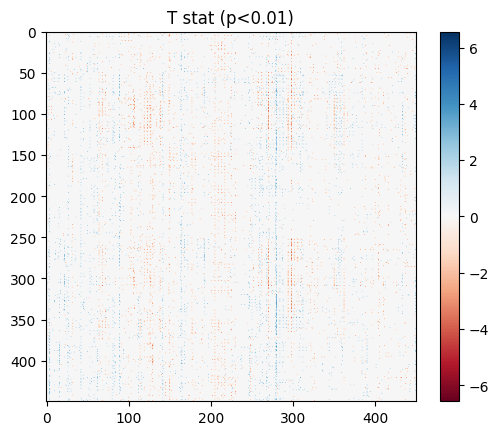

In [34]:
plt.imshow(sigt, cmap='RdBu', vmin=-np.abs(sigt).max(), vmax=np.abs(sigt).max())
plt.colorbar()
plt.title("T stat (p<0.01)")

Text(0.5, 1.0, 'Summed Attention Weights T-stat')

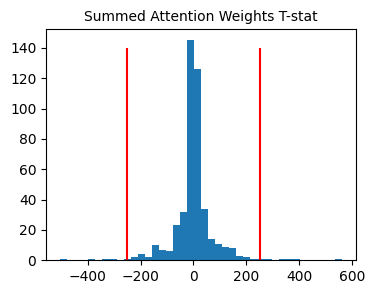

In [26]:
plt.figure(figsize=[4,3])
plt.hist(sigt.sum(axis=0), bins=40)
plt.vlines(3*sigt.sum(axis=0).std(), ymin=0, ymax=140, color='red')
plt.vlines(-3*sigt.sum(axis=0).std(), ymin=0, ymax=140, color='red')
plt.title("Summed Attention Weights T-stat", fontsize=10)

In [38]:
# use t-stat or p-value as threshold (I think t-stat is better)
thr = 3*np.std(np.abs(sigt).sum(axis=0))
inds, = np.where(np.abs(sigt).sum(axis=0)>thr)
metric = np.abs(sigt).sum(axis=0)

#thr = 3*np.std(sigp.sum(axis=0))
#inds, = np.where(sigt.sum(axis=0)>thr)

NameError: name 'sigt' is not defined

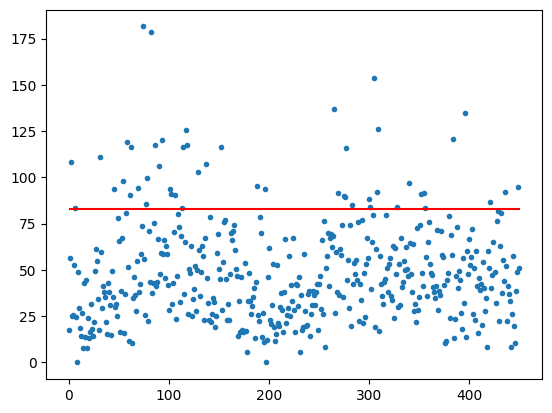

In [36]:
plt.plot(np.abs(sigt).sum(axis=1), '.')
plt.hlines(thr, xmin=0, xmax=450, color='red')

In [37]:
# re-org ROI indices: ctx_L, sub-ctx_L, ctx_R, sub-ctx_R
reverse_roi_inds = np.concatenate([np.arange(50,250), np.arange(25,50), np.arange(250,450), np.arange(0, 25)])

with open(os.path.join(proj_dir, 'parcellations', 'atlas_config.json'), 'r') as f:
    atlas_config = json.load(f)

node_names = np.array(atlas_config['schaefer400_tianS3']['node_names'])[reverse_roi_inds[inds]]
node_ids = np.array(atlas_config['schaefer400_tianS3']['node_ids'])[reverse_roi_inds[inds]]

NameError: name 'inds' is not defined

Node index   53 Left_SomMotB_Aud_10            	 : 	 90.23 	 Metric index = 2
Node index   82 Left_DorsAttnB_FEF_1           	 : 	 107.00 	 Metric index = 31
Node index   96 Left_SalVentAttnA_ParMed_2     	 : 	 101.58 	 Metric index = 45
Node index  105 Left_SalVentAttnB_PFCv_2       	 : 	 103.20 	 Metric index = 54
Node index  109 Left_Limbic_OFC_1              	 : 	 105.76 	 Metric index = 58
Node index  112 Left_Limbic_OFC_4              	 : 	 85.05 	 Metric index = 61
Node index  113 Left_Limbic_OFC_5              	 : 	 113.64 	 Metric index = 62
Node index  120 Left_Limbic_TempPole_7         	 : 	 88.27 	 Metric index = 69
Node index  125 Left_ContA_IPS_4               	 : 	 194.44 	 Metric index = 74
Node index  129 Left_ContA_PFCl_2              	 : 	 105.03 	 Metric index = 78
Node index  133 Left_ContA_Cinga_1             	 : 	 170.35 	 Metric index = 82
Node index  137 Left_ContB_IPL_2               	 : 	 112.01 	 Metric index = 86
Node index  141 Left_ContB_PFClv_2          

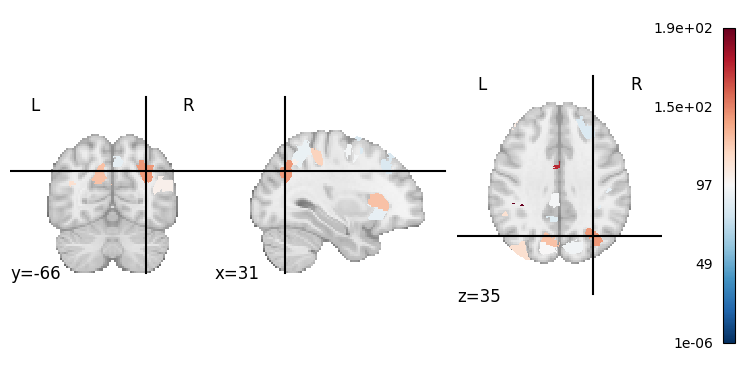

In [29]:
atlas = nilearn.image.load_img(os.path.join(proj_dir, 'parcellations', 'schaefer400_tianS3MNI_lps_mni.nii.gz'))

attn_map = np.zeros(atlas.get_fdata().shape)

for i,node in enumerate(node_ids):
    x,y,z = np.where(atlas.get_fdata()==node)
    attn_map[x,y,z] = metric[roi_inds[node-1]]
    print(f"Node index {node:4} {node_names[i]:30} \t : \t {metric[roi_inds[node-1]]:.2f} \t Metric index = {roi_inds[node-1]}")

attn_img = nilearn.image.new_img_like(atlas, attn_map)

nilearn.plotting.plot_stat_map(attn_img, cmap='RdBu_r')#, cut_coords=[-44, 50, 4])

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)



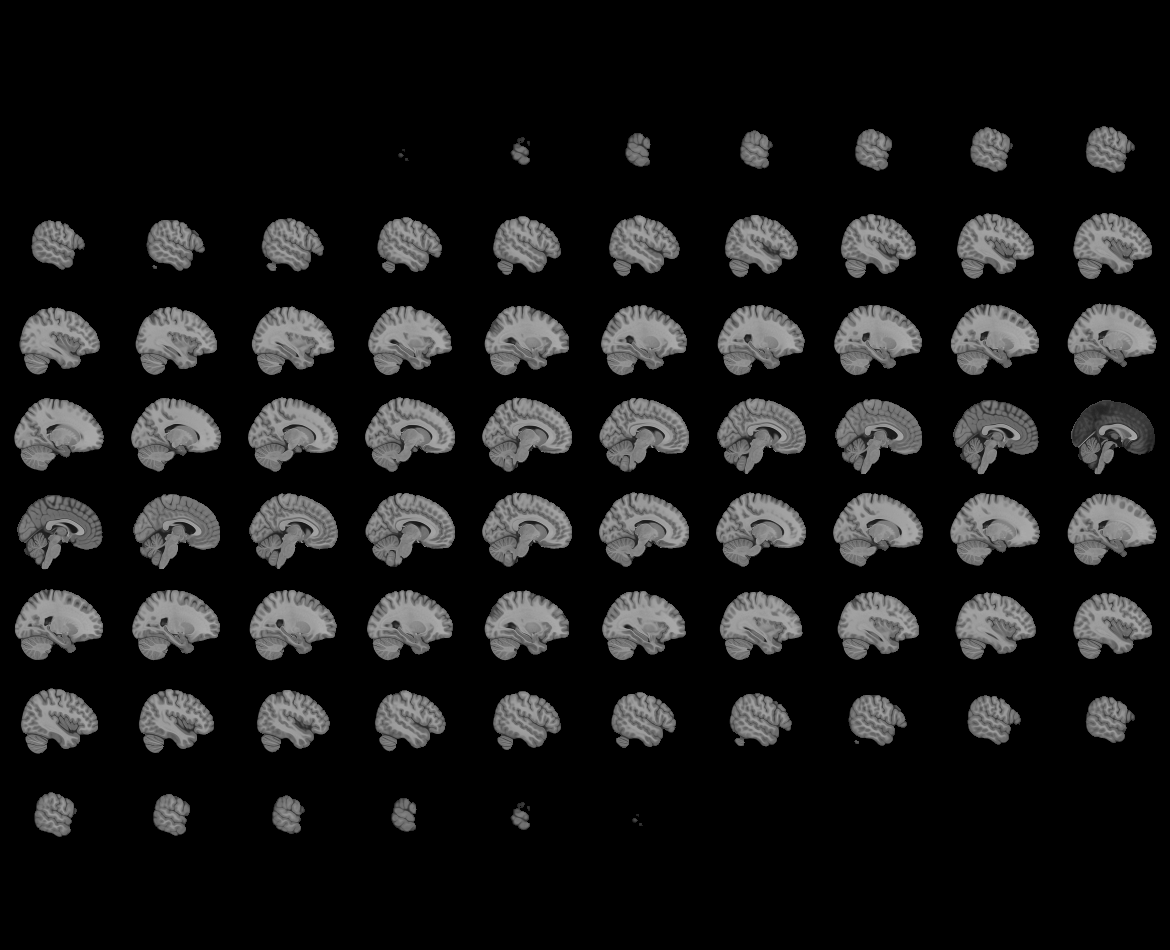
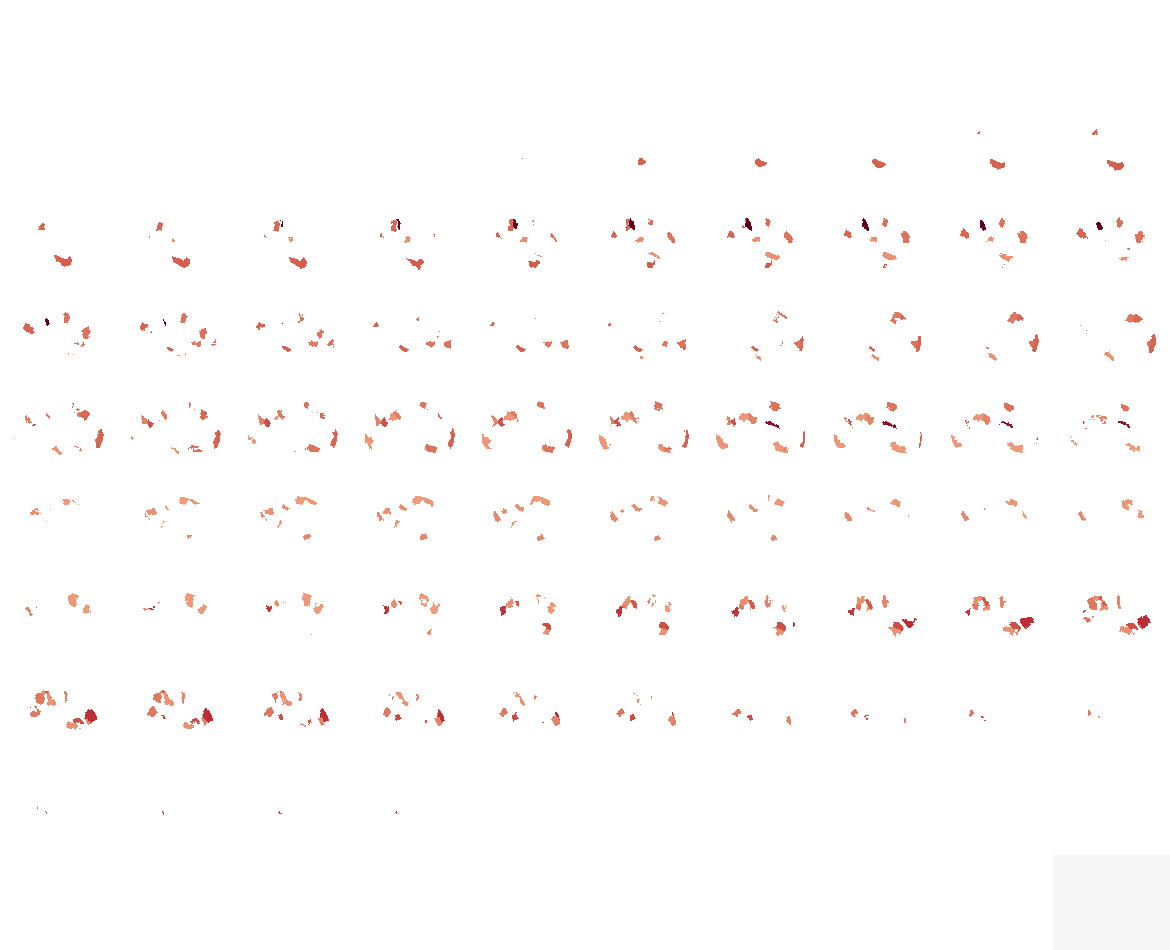

In [30]:
nilearn.plotting.view_img(attn_img, cmap='RdBu_r')

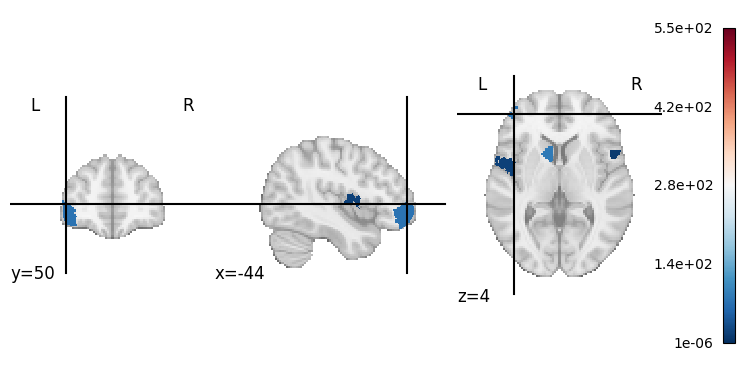

In [33]:
nilearn.plotting.plot_stat_map(attn_img, cmap='RdBu_r', cut_coords=[-44, 50, 4])

In [14]:
all_perceiver_attn = torch.cat(perciever_attn, dim=0).cpu()

In [13]:
importlib.reload(OCD_symphony.attention_analysis.attention_weights_analysis)
importlib.reload(OCD_symphony.attention_analysis)
importlib.reload(OCD_symphony)

<module 'OCD_symphony' from '/home/sebastin/working/lab_lucac/sebastiN/projects/OCD_Symphony/src/OCD_symphony/__init__.py'>

=== HEAD 0 ===
Node index   55 	 Left_SomMotB_Aud_12            	 : 	 304.06 	 Metric index = 4
Node index   93 	 Left_SalVentAttnA_Ins_5        	 : 	 302.65 	 Metric index = 42
Node index  115 	 Left_Limbic_TempPole_2         	 : 	 215.31 	 Metric index = 64
Node index  140 	 Left_ContB_PFClv_1             	 : 	 321.60 	 Metric index = 89
Node index  201 	 Left_Hippocampus-Head-Medial   	 : 	 241.96 	 Metric index = 150
Node index  215 	 Left_VentroanteriorCaudate     	 : 	 302.90 	 Metric index = 164
Node index   31 	 Left_SomMotA_7                 	 : 	 357.51 	 Metric index = 205
Node index   43 	 Left_SomMotA_19                	 : 	 241.68 	 Metric index = 217
Node index  294 	 Right_DorsAttnA_SPL_6          	 : 	 245.44 	 Metric index = 268
Node index  296 	 Right_DorsAttnA_SPL_8          	 : 	 401.20 	 Metric index = 270
Node index  305 	 Right_DorsAttnB_PostC_7        	 : 	 408.42 	 Metric index = 279
Node index  306 	 Right_DorsAttnB_PostC_8        	 : 	 568.11 	 Metric index 

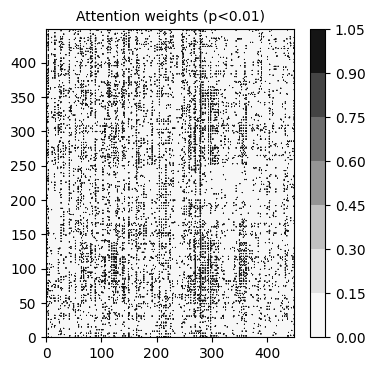

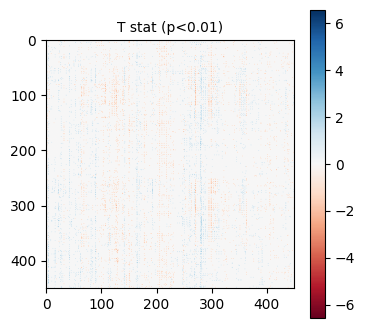

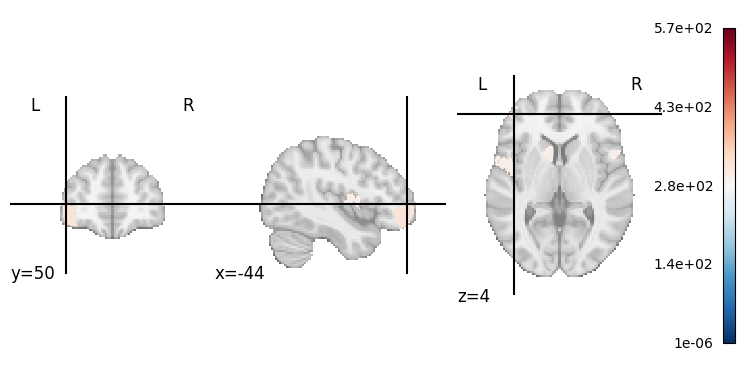

In [31]:
attn_heads = []
for head in [0]:
    print(f"=== HEAD {head} ===")
    t0 = time()
    res = OCD_symphony.attention_analysis.compute_weights_ttest(all_perceiver_attn, labels=labels, head=0)
    
    sigp, (row,col) = OCD_symphony.attention_analysis.compute_significant_pval(res)
    OCD_symphony.attention_analysis.plot_significant_pvals(sigp)
    
    sigt = OCD_symphony.attention_analysis.compute_significant_tstat(res, row, col)
    OCD_symphony.attention_analysis.plot_significant_tstat(sigt)
    
    attn_img = OCD_symphony.attention_analysis.create_attention_brain_image(sigvals=sigt, roi_inds=roi_inds)
    OCD_symphony.attention_analysis.plot_attention_brain_image(attn_img)

    attn_heads.append((res, attn_img))
    
    t1 = time()-t0
    print(f"=== DONE in {t1:.1f}s")

In [17]:
import pickle
with open(os.path.join(proj_dir, 'results', 'attention_heads_20251202.pkl'), 'wb') as f:
    pickle.dump(attn_heads, f)

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)



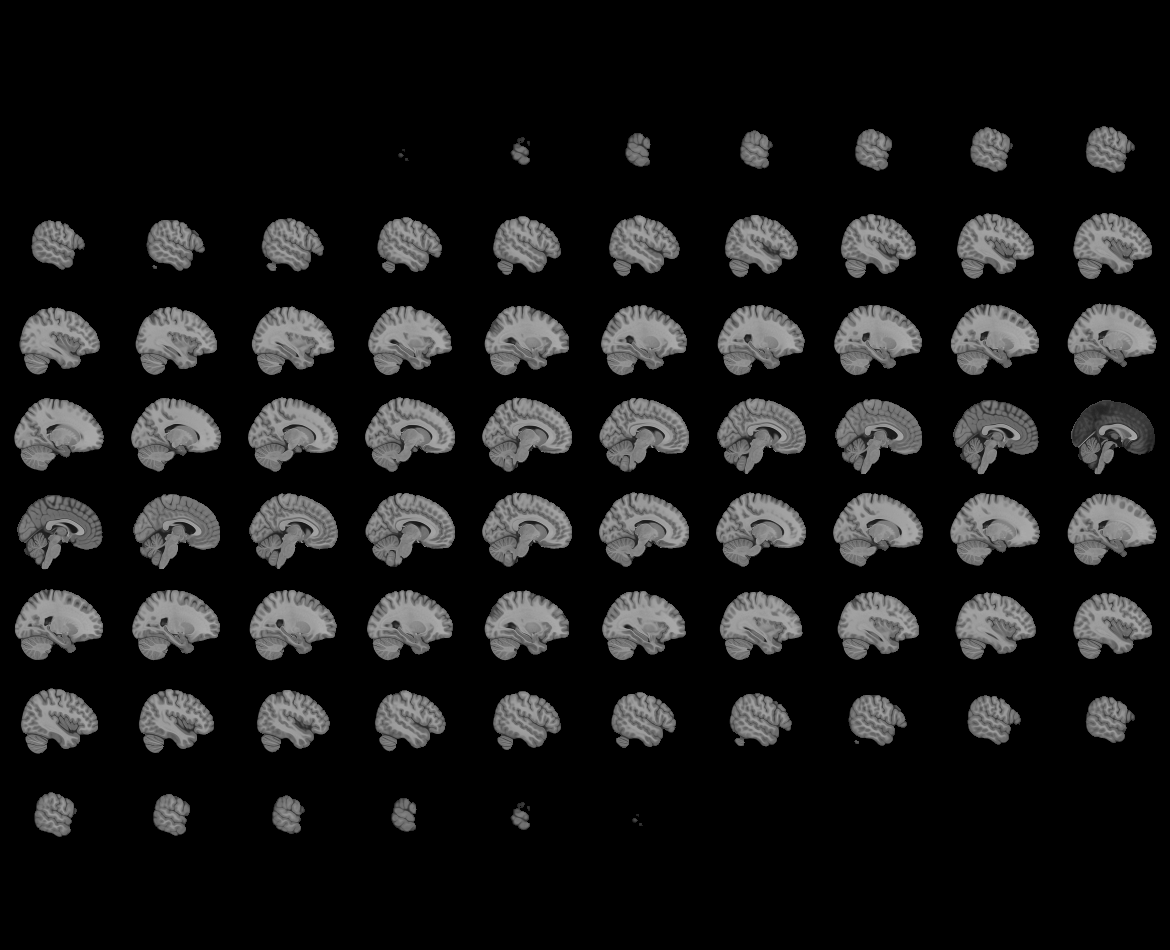
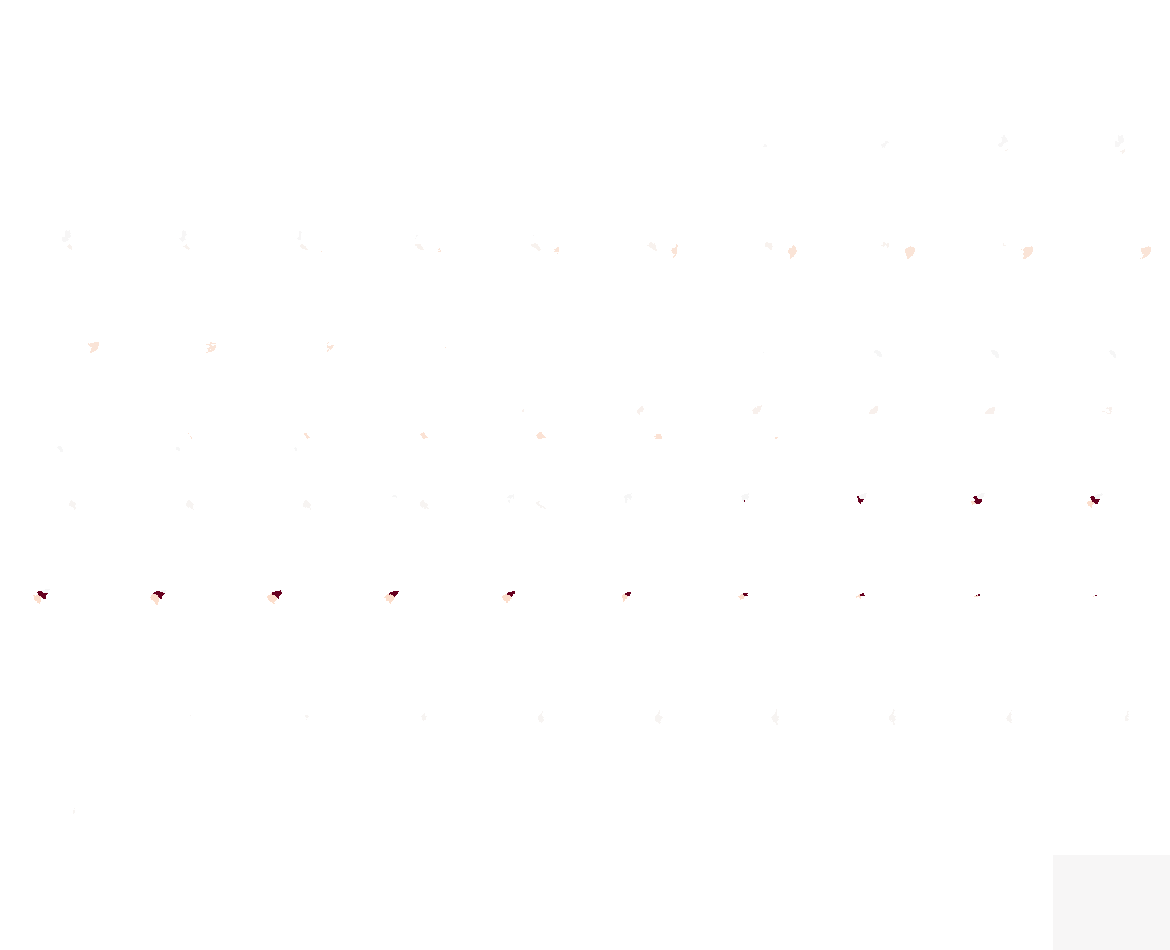

In [18]:
nilearn.plotting.view_img(attn_img, cmap='RdBu_r')

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)



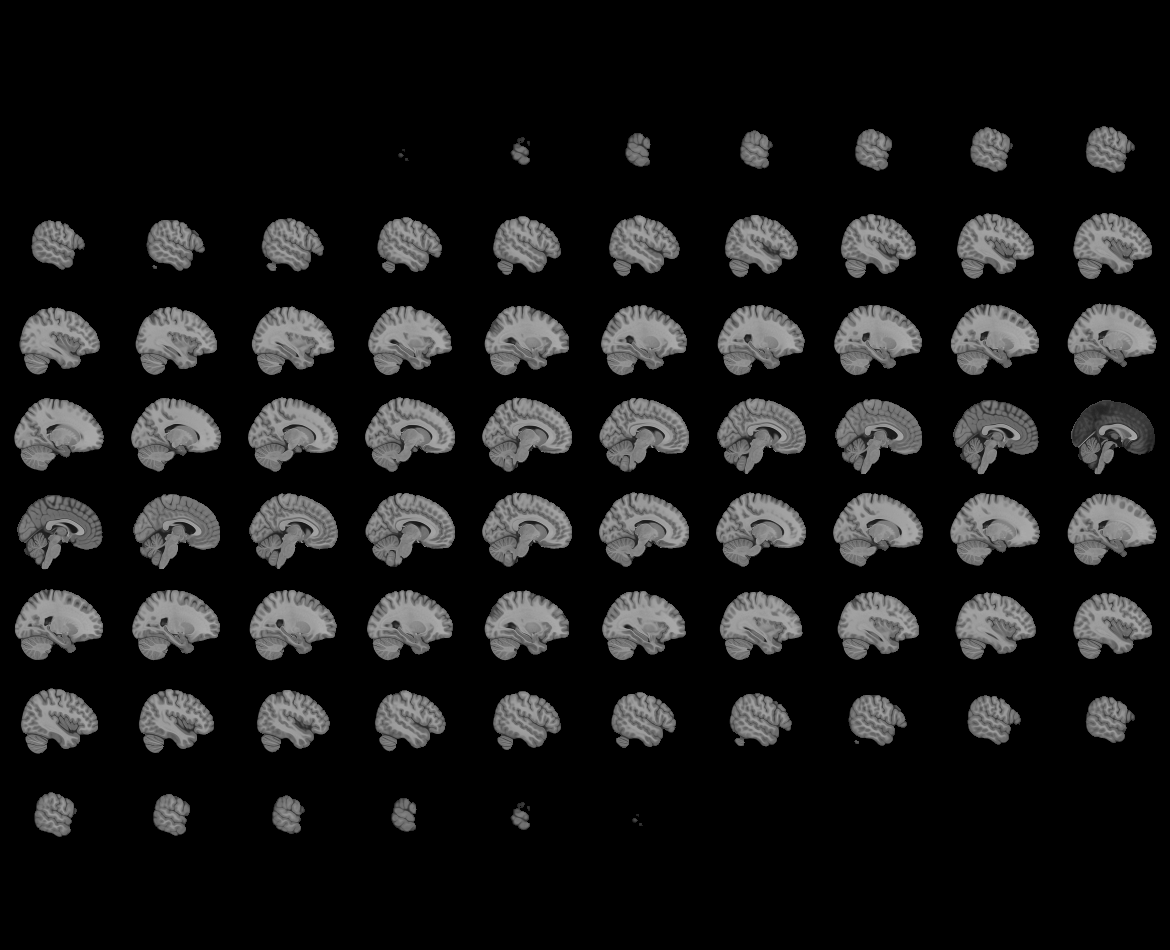
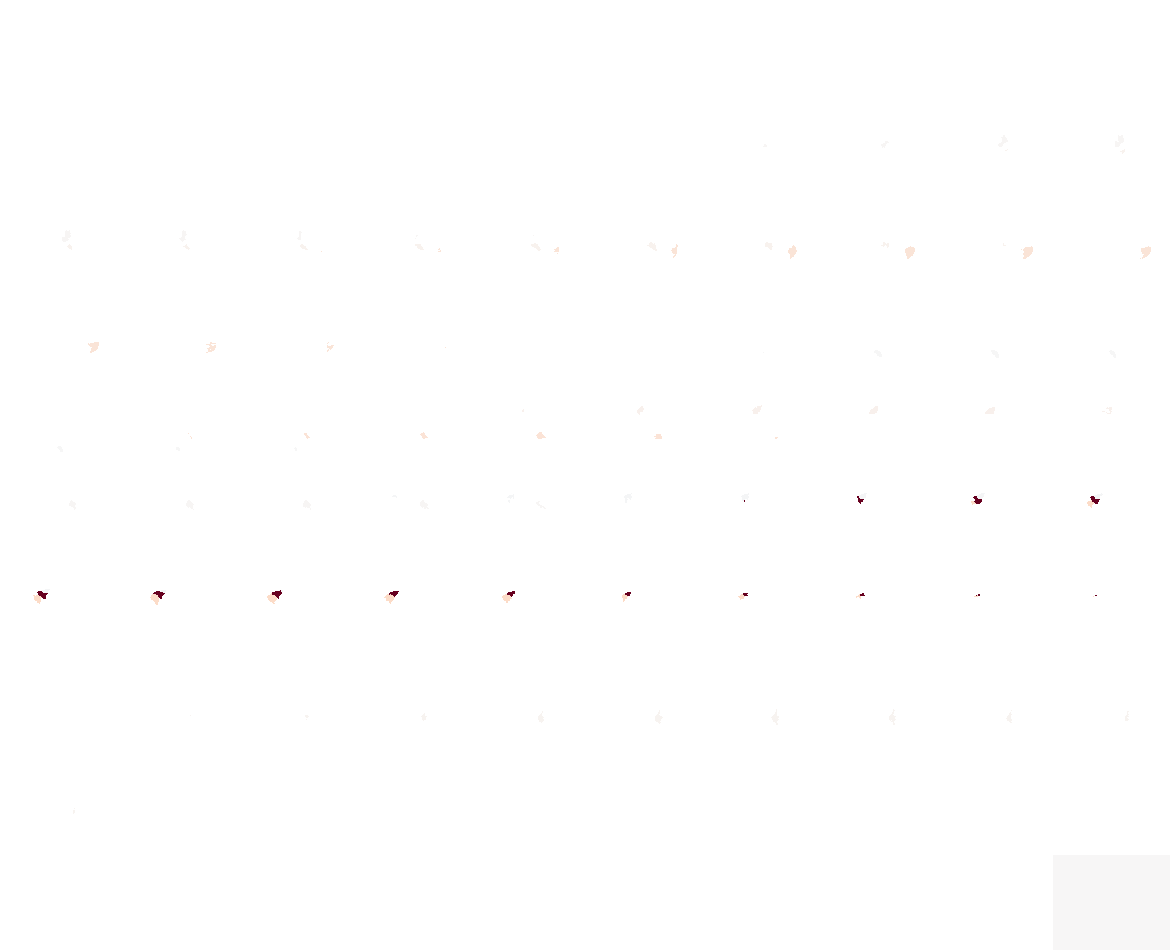

In [20]:
nilearn.plotting.view_img(attn_heads[0][1], cmap='RdBu_r')

Showing attention weights for the 5 regions with highest aggregated T-stat (sum of absolute T values).
Metric index 280  -->  Right_DorsAttnB_PostC_8
Atlas index  154 	 Left_DefaultA_PCC_1            	 : 	 -3.64 	 Metric index 103
Metric index 298  -->  Right_SalVentAttnA_ParMed_4
Metric index 279  -->  Right_DorsAttnB_PostC_7
Atlas index  324 	 Right_SalVentAttnA_ParMed_4    	 : 	 -4.08 	 Metric index 298
Atlas index  385 	 Right_DefaultA_IPL_2           	 : 	 3.85 	 Metric index 359
Metric index 270  -->  Right_DorsAttnA_SPL_8
Atlas index   93 	 Left_SalVentAttnA_Ins_5        	 : 	 3.63 	 Metric index 42
Metric index 205  -->  Left_SomMotA_7
Showing attention weights for the 5 regions with highest aggregated T-stat (sum of absolute T values).
Metric index 74  -->  Left_ContA_IPS_4
Atlas index  123 	 Left_ContA_IPS_2               	 : 	 -3.81 	 Metric index 72
Atlas index  133 	 Left_ContA_Cinga_1             	 : 	 3.60 	 Metric index 82
Atlas index  140 	 Left_ContB_PFClv_1          

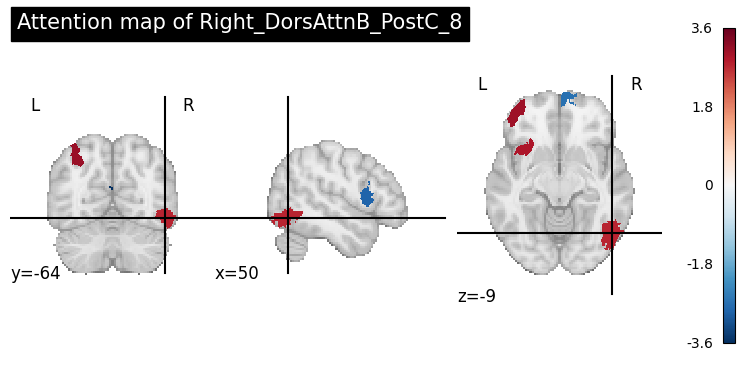

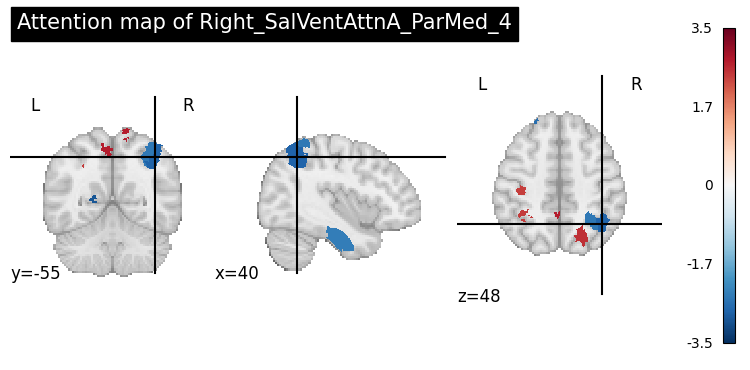

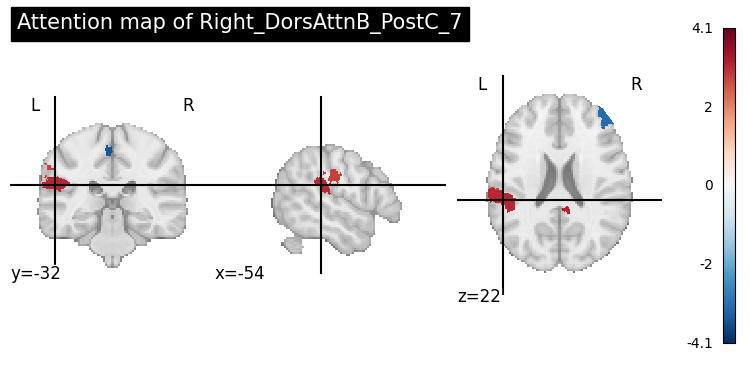

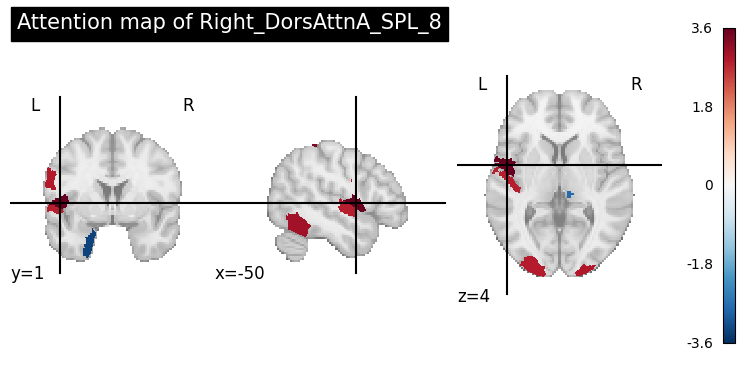

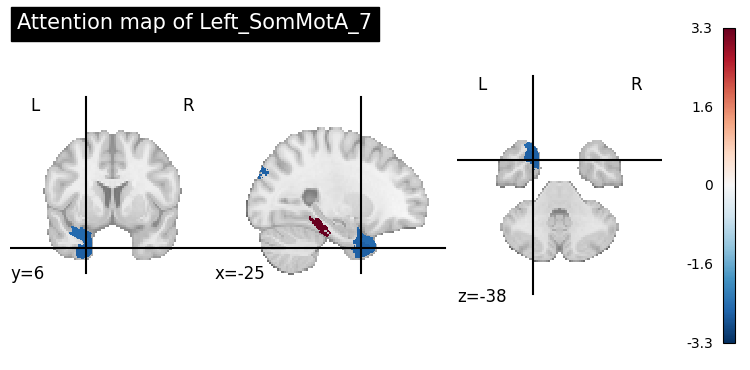

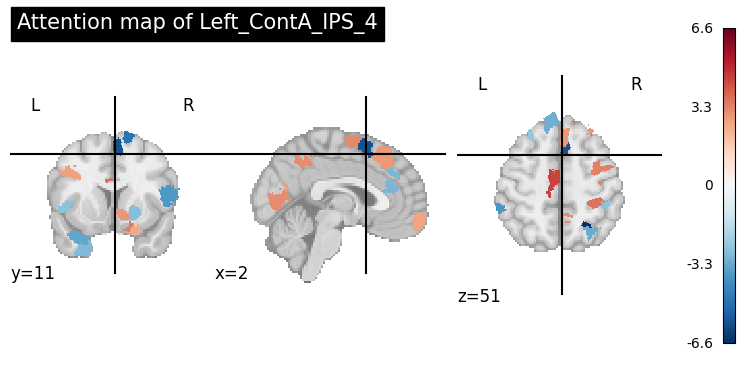

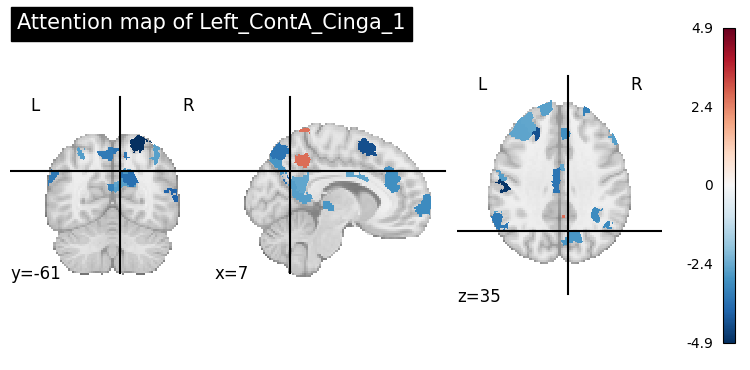

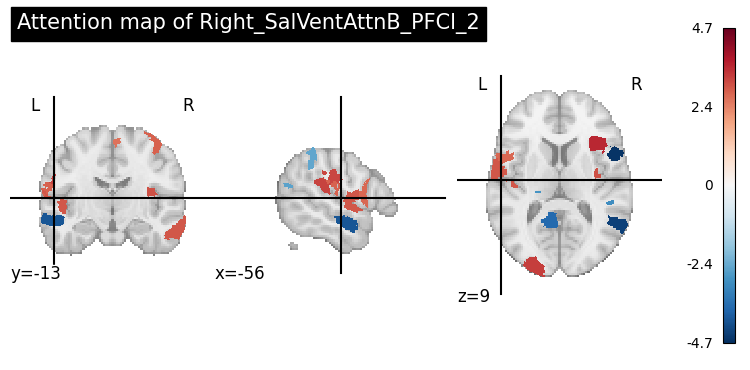

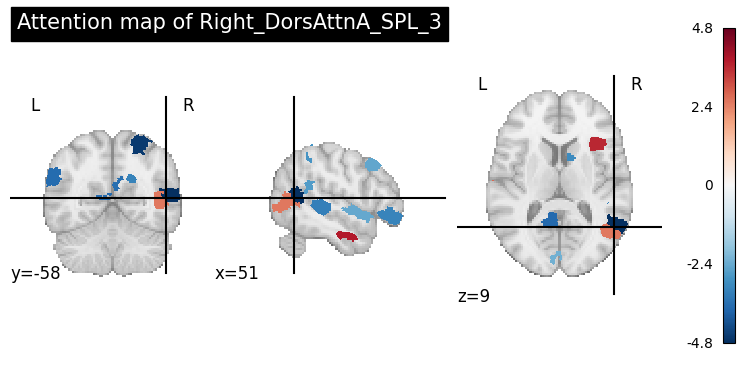

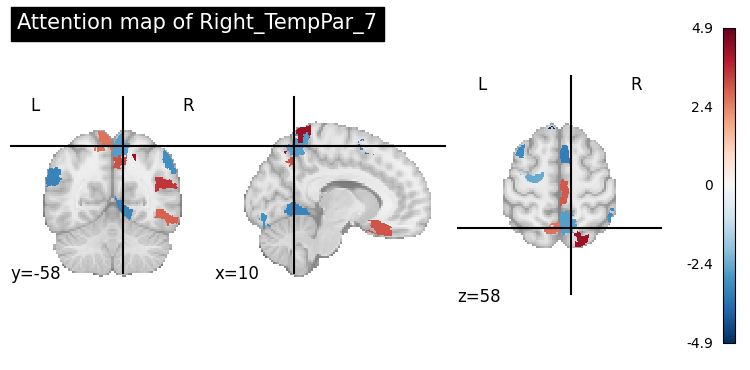

In [77]:
t_threshold = 3.5

features = dict()
for axis, dim in enumerate(['row-wise', 'column-wise']):
    feature_inds = dict()
    sorted_inds = np.argsort(np.abs(sigt).sum(axis=axis))[::-1]
    #metric = sigt[max_ind]
    
    n_highest = 5
    
    node_names = np.array(atlas_config['schaefer400_tianS3']['node_names'])[reverse_roi_inds]
    node_ids = np.array(atlas_config['schaefer400_tianS3']['node_ids'])[reverse_roi_inds]
    
    print(f"Showing attention weights for the {n_highest} regions with highest aggregated T-stat (sum of absolute T values).")
    
    
    for ind in sorted_inds[:n_highest]:
        print(f"Metric index {ind}  -->  {node_names[ind]}")
        metric = sigt[ind]
        feature_inds[ind] = []
        
        # create brain img
        attn_map = np.zeros(atlas.get_fdata().shape)
        for i,node in enumerate(node_ids):
            x,y,z = np.where(atlas.get_fdata()==node)
            
            attn_map[x,y,z] = metric[roi_inds[node-1]]
            if np.abs(metric[roi_inds[node-1]])>t_threshold:
                print(f"Atlas index {node:4} \t {node_names[i]:30} \t : \t {metric[roi_inds[node-1]]:.2f} \t Metric index {roi_inds[node-1]}")
                feature_inds[ind].append(roi_inds[node-1])
        
        feature_inds[ind] = np.array(feature_inds[ind])
        
        attn_img = nilearn.image.new_img_like(atlas, attn_map)
        nilearn.plotting.plot_stat_map(attn_img, cmap='RdBu_r', title=f"Attention map of {node_names[ind]}")
        #nilearn.plotting.view_img(attn_img, cmap='RdBu_r', title=f"Attention map of {node_names[ind]}")
    
    features[(axis, dim)] = feature_inds

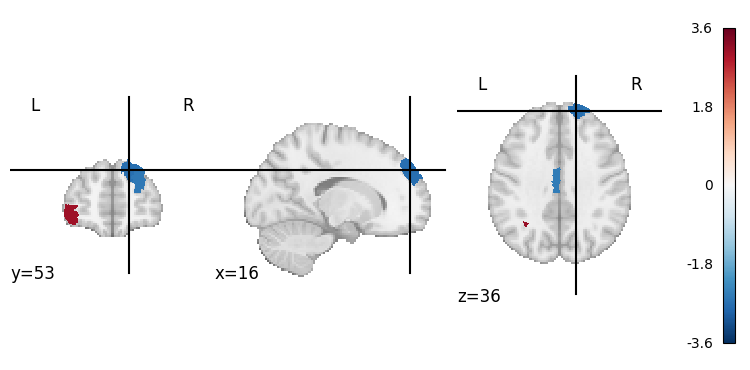

In [31]:
nilearn.plotting.plot_stat_map(attn_img, cmap='RdBu_r', cut_coords=[16, 53, 36])

In [36]:
max_ind = np.argsort(np.abs(sigt).sum(axis=0))[::-1][1]

In [33]:
help(nilearn.plotting.plot_stat_map)

Help on function plot_stat_map in module nilearn.plotting.img_plotting:

plot_stat_map(stat_map_img, bg_img=<MNI152Template>, cut_coords=None, output_file=None, display_mode='ortho', colorbar=True, cbar_tick_format='%.2g', figure=None, axes=None, title=None, threshold=1e-06, annotate=True, draw_cross=True, black_bg='auto', cmap=<matplotlib.colors.LinearSegmentedColormap object at 0x761baaa51160>, symmetric_cbar='auto', dim='auto', vmin=None, vmax=None, radiological=False, resampling_interpolation='continuous', **kwargs)
    Plot cuts of an ROI/mask image.
    
    By default 3 cuts: Frontal, Axial, and Lateral.
    
    Parameters
    ----------
    stat_map_img : Niimg-like object
        See :ref:`extracting_data`.
        The statistical map image
    
    bg_img : Niimg-like object, optional
        See :ref:`extracting_data`.
        The background image to plot on top of.
        If nothing is specified, the MNI152 template will be used.
        To turn off background image, just

## Load attention results

In [14]:
import pickle
with open(os.path.join(proj_dir, 'results', 'attention_heads_20251202.pkl'), 'rb') as f:
    attn_heads = pickle.load(f)

In [15]:
res = attn_heads[0][0]

In [18]:
max_ind = np.argmax(attn_heads[0][0][0].sum(axis=0))

# Classification using Attention Heads

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, StratifiedGroupKFold, GroupShuffleSplit, cross_validate
from sklearn.metrics import accuracy_score, roc_auc_score

# input : post-cuneus attention weights
max_ind = np.argmax(np.abs(attn_heads[0][0][0]).sum(axis=0))
print(f"max_ind={max_ind}")
X = all_perceiver_attn[:,0,max_ind,:].squeeze()   ## shape (n_samples,450)

# labels : ocd vs controls
y = np.array([0 if 'control' in s else 1 for s in subjs])
#y = emb_data['genders']

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)

# use a a small subset of the dataset
#n_samples = 16
#hc_inds = np.random.permutation(np.where(~y.astype(bool))[0])#[:n_samples]
#ocd_inds = np.random.permutation(np.where(y.astype(bool))[0])#[:n_samples]
#inds = np.concatenate([hc_inds, ocd_inds])
#X = X[inds,:,:]
#y = y[inds]
#groups = groups[inds]

# 1) Pool ROIs to get one 128-d vector per subject
X_pooled = X            # shape: (n_samples, 450)
#X_flattened = X.reshape(X.shape[0], X.shape[1]*X.shape[2]) 

# 2) Pipeline: scale -> elastic-net logistic regression
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=10000,
        l1_ratio=0.5,        # tuned via grid below
        C=1.0,               # tuned via grid below
    ))
])

# 3) Hyperparam search with nested CV (small grid to keep it stable)
param_grid = {
    "clf__C": [0.1, 0.3, 1.0, 3.0, 10.0],
    "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0)

search = GridSearchCV(pipe, param_grid, cv=list(inner.split(X_pooled, y, groups)), scoring="accuracy", n_jobs=32, verbose=1)
search.fit(X_pooled, y, groups=groups)

print(f"Best params: {search.best_params_}")

outer = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)
scores = sklearn.model_selection.cross_validate(search.best_estimator_, X_pooled, y, groups=groups, cv=outer, n_jobs=32, verbose=0, return_train_score=True)

print(f"Training accuracy \t = \t {scores['train_score'].mean():.3f} ± {scores['train_score'].std():.3f}")
print(f"Test accuracy \t\t = \t {scores['test_score'].mean():.3f} ± {scores['test_score'].std():.3f}")

max_ind=280
Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best params: {'clf__C': 0.1, 'clf__l1_ratio': 0.5}
Training accuracy 	 = 	 0.889 ± 0.005
Test accuracy 		 = 	 0.516 ± 0.039


## Post-hoc selection of weights based on |T-stats|>3 

In [16]:
with open(os.path.join(proj_dir, 'parcellations', 'atlas_config.json'), 'r') as f:
    atlas_config = json.load(f)
    
node_names = np.array(atlas_config['schaefer400_tianS3']['node_names'])[roi_inds]
node_ids = np.array(atlas_config['schaefer400_tianS3']['node_ids'])[roi_inds]

In [32]:
inds = []

# 280 (R_PostC) -> 103 (L_PCC) 89 (L_PFClv) 73 (L_IPS)
inds.append({280: np.array([73, 89, 103])})

# 298 (R_parMed) —> 22 (L_PostC) , 210 (L_SomMot_12), 224 (L_Aud), 284 (R_ParOper), 
inds.append({298: np.array([22, 210, 224, 284])})

# 270 (R_SPL) —> 11 (L_TempOcc), 26 (L_PostC), 42 (L_Ins), 64 (L_TempPole), 
inds.append({270: np.array([11, 26, 42, 64])})

# 279 (R_PostC) —> 35 (L_ParOper) 138 (L_Rsp), 164 (L_vaCaud), 192 (R_ExStrSup), 207 (L_SomMotA), 278 (R_PostC), 287 (R_PrC), 298 (R_ParMed), 305 (R_PFCl), 355 (R_Cingp), 359 (R_IPL)
inds.append({279: np.array([35, 138, 164, 192, 207, 278, 287, 298, 305, 355, 359])})

# 42 (L_Ins) —> 114 (L_PFCm), 163 (L_dpPut), 164 (L_vaCaud)
inds.append({42: np.array([114, 163, 164])})


hc_inds, = np.where(labels==0)
ocd_inds, = np.where(labels==1)

df = []
for sinds in inds:
    for i,js in sinds.items():
        for j in js:
            for g_inds, grp in zip([hc_inds, ocd_inds], ['healthy', 'OCD']):
                for w in all_perceiver_attn[g_inds,0,i,j]:
                    line = {'to':i, 'from':j, 'to_lbl':node_names[i], 'from_lbl':node_names[j], 'weights':float(w), 'group': grp}
                    df.append(line)
df = pd.DataFrame(df)
df  

,to,from,to_lbl,from_lbl,weights,group
0,280,73,Right_SomMotA_8,Left_VisPeri_ExStrSup_12,0.004853,healthy
1,280,73,Right_SomMotA_8,Left_VisPeri_ExStrSup_12,0.001166,healthy
2,280,73,Right_SomMotA_8,Left_VisPeri_ExStrSup_12,0.002841,healthy
3,280,73,Right_SomMotA_8,Left_VisPeri_ExStrSup_12,0.004087,healthy
4,280,73,Right_SomMotA_8,Left_VisPeri_ExStrSup_12,0.002459,healthy
...,...,...,...,...,...,...
9795,42,164,Left_Caudate-Tail,Left_Limbic_TempPole_2,0.000986,OCD
9796,42,164,Left_Caudate-Tail,Left_Limbic_TempPole_2,0.002315,OCD
9797,42,164,Left_Caudate-Tail,Left_Limbic_TempPole_2,0.003294,OCD
9798,42,164,Left_Caudate-Tail,Left_Limbic_TempPole_2,0.003148,OCD


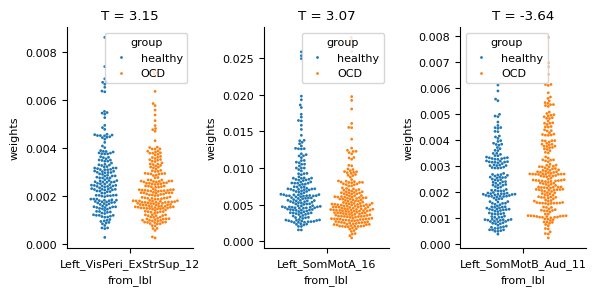

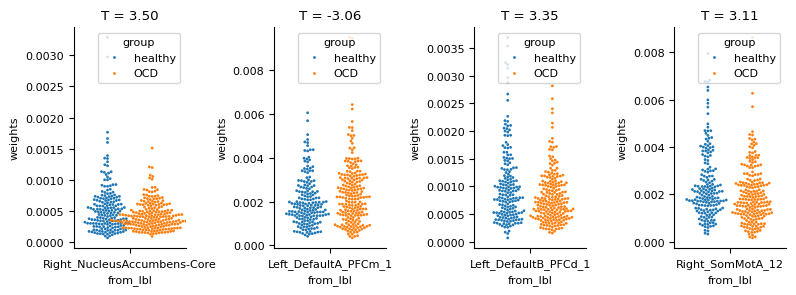

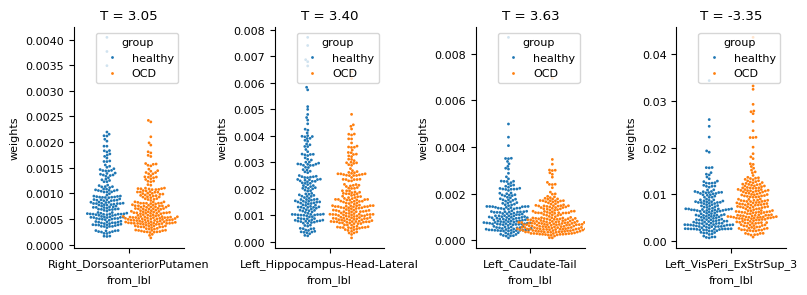

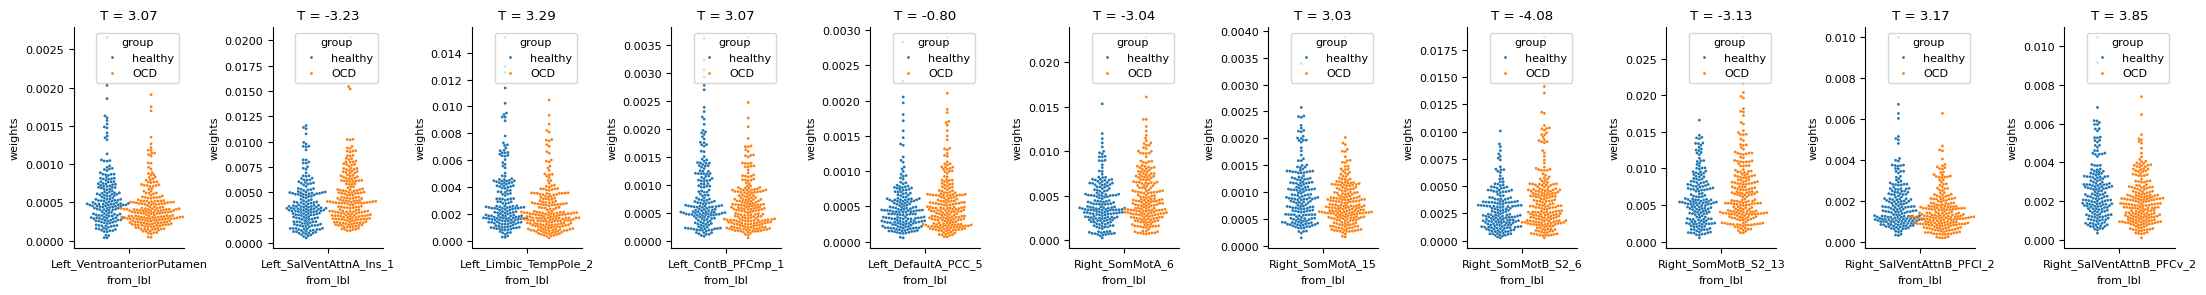

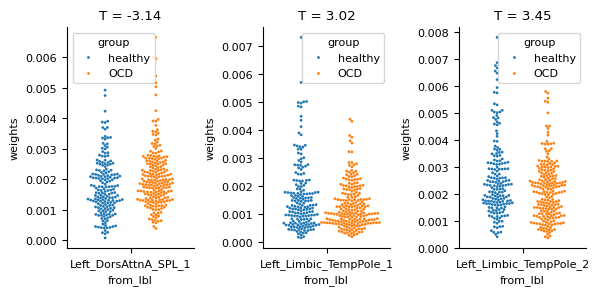

In [48]:
plt.rcParams.update({'font.size':8})

for i, to_lbl in enumerate(df.to_lbl.unique()):
    data = df[df.to_lbl==to_lbl]
    n_cols = len(data.from_lbl.unique())
    
    fig = plt.figure(figsize=[2*n_cols,3])
    
    for j, from_lbl in enumerate(data.from_lbl.unique()):
        d = data[data.from_lbl==from_lbl]
        
        ax = plt.subplot(1,n_cols, j+1)
        sbn.swarmplot(data=d, x='from_lbl', y='weights', hue='group', dodge=True, ax=ax, s=2)
        tcks = ax.get_xticks()
        lbls = ax.get_xticklabels()
        #ax.set_xticks(tcks, lbls, rotation=30)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        res = scipy.stats.ttest_ind(np.array(d[d.group=='healthy'].weights), np.array(d[d.group=='OCD'].weights), equal_var=False, permutations=100)
        plt.title(f"T = {res.statistic:.2f}")

    plt.tight_layout()


In [45]:
feature_inds

{74: array([ 72,  82,  89, 139, 206, 258, 262, 270, 277, 294, 298, 302, 357,
        449]),
 82: array([ 23,  68, 100, 107, 119, 127, 206, 258, 262, 270, 294, 298, 302,
        350, 354, 357]),
 305: array([ 68, 119, 127, 139, 258, 262, 270, 294, 298, 309, 350, 382]),
 265: array([ 68, 119, 123, 127, 139, 262, 270, 298, 309, 357, 362]),
 396: array([ 72,  81,  89, 127, 256, 268, 280, 284, 288])}

In [19]:

X = []
for k in range(all_perceiver_attn.shape[0]):
    line = []
    for row, col in zip(rows, cols):
        line.append(all_perceiver_attn[k,0,row,col])
    X.append(line)
X = np.array(X)
X.shape

(392, 242)

In [78]:

X1 = []
feature_inds = features[(0,'row-wise')]
for k in range(all_perceiver_attn.shape[0]):
    row = []
    for i in feature_inds.keys():
        for j in feature_inds[i]:
            row.append(float(all_perceiver_attn[k,0,j,i]))
    X1.append(row)

X2 = []
feature_inds = features[(1,'column-wise')]
for k in range(all_perceiver_attn.shape[0]):
    row = []
    for i in feature_inds.keys():
        for j in feature_inds[i]:
            row.append(float(all_perceiver_attn[k,0,i,j]))
    X2.append(row)
    
X = np.concatenate([X1,X2], axis=1)
X.shape

(392, 66)

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, StratifiedGroupKFold, GroupShuffleSplit, cross_validate
from sklearn.metrics import accuracy_score, roc_auc_score

# labels : ocd vs controls
y = np.array([0 if 'control' in s else 1 for s in subjs])
#y = emb_data['genders']

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)

# use a a small subset of the dataset
#n_samples = 16
#hc_inds = np.random.permutation(np.where(~y.astype(bool))[0])#[:n_samples]
#ocd_inds = np.random.permutation(np.where(y.astype(bool))[0])#[:n_samples]
#inds = np.concatenate([hc_inds, ocd_inds])
#X = X[inds,:,:]
#y = y[inds]
#groups = groups[inds]

# 1) Pool ROIs to get one 128-d vector per subject
X_pooled = X            # shape: (n_samples, 450)
#X_flattened = X.reshape(X.shape[0], X.shape[1]*X.shape[2]) 

# 2) Pipeline: scale -> elastic-net logistic regression
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=10000,
        l1_ratio=0.5,        # tuned via grid below
        C=1.0,               # tuned via grid below
    ))
])

# 3) Hyperparam search with nested CV (small grid to keep it stable)
param_grid = {
    "clf__C": [0.1, 0.3, 1.0, 3.0, 10.0],
    "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0)

search = GridSearchCV(pipe, param_grid, cv=list(inner.split(X_pooled, y, groups)), scoring="accuracy", n_jobs=32, verbose=1)
search.fit(X_pooled, y, groups=groups)

print(f"Best params: {search.best_params_}")

outer = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)
scores = sklearn.model_selection.cross_validate(search.best_estimator_, X_pooled, y, groups=groups, cv=outer, n_jobs=32, verbose=0, return_train_score=True, return_estimator=True)

print(f"Training accuracy \t = \t {scores['train_score'].mean():.3f} ± {scores['train_score'].std():.3f}")
print(f"Test accuracy \t\t = \t {scores['test_score'].mean():.3f} ± {scores['test_score'].std():.3f}")

Fitting 3 folds for each of 25 candidates, totalling 75 fits


/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/joblib/externals/loky/initializers.py:28: UserWarning: Unable to introspect viztracer state: [Errno 107] Transport endpoint is not connected
  warnings.warn(f"Unable to introspect viztracer state: {e}")


OSError: [Errno 107] Transport endpoint is not connected

In [23]:
np.arange(12).reshape(3,4).sum(axis=1).shape

(3,)

In [40]:
T = res[0]
rows, cols = np.where(np.abs(T)>4)
for row,col in zip(rows, cols):
    print(f"{node_names[row]:40} attends to {node_names[col]:40} with T={T[row,col]:.2f} (OCD vs healthy)")
    

Right_Hippocampus-Head-Lateral           attends to Left_DefaultA_PFCd_2                     with T=-4.01 (OCD vs healthy)
Right_Hippocampus-Head-Lateral           attends to Left_DefaultA_PCC_3                      with T=-4.35 (OCD vs healthy)
Right_Hippocampus-Body                   attends to Left_SomMotB_Aud_15                      with T=-4.20 (OCD vs healthy)
Right_Hippocampus-Body                   attends to Right_SomMotA_8                          with T=4.37 (OCD vs healthy)
Right_LateralVentroposteriorThalamus     attends to Left_DefaultA_PCC_3                      with T=-4.07 (OCD vs healthy)
Right_InferiorVentroanteriorThalamus     attends to Right_VisPeri_ExStrSup_7                 with T=4.51 (OCD vs healthy)
Right_Caudate-Tail                       attends to Left_DefaultA_PFCm_4                     with T=-4.57 (OCD vs healthy)
Right_Caudate-Tail                       attends to Left_DefaultB_Temp_2                     with T=-4.05 (OCD vs healthy)
Left_Hippocampus-H

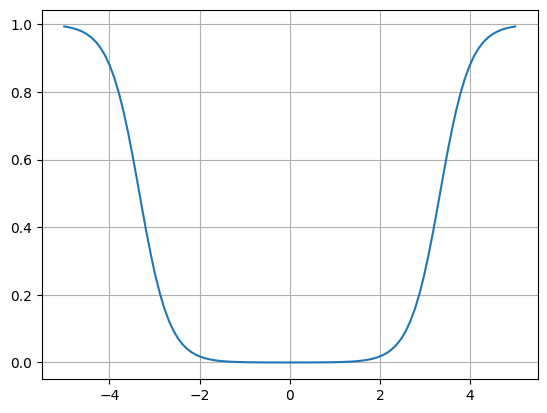

In [72]:
a = 3; b = 10;
x = np.linspace(-5, 5, 100)
y = 1 / (1 + np.exp(-a*np.abs(x)+b))

plt.plot(x,y)
plt.grid()

In [41]:
def T_filter_func(T, a=3, b=10):
    return 1 / (1 + np.exp(-a*np.abs(T)+b))
    

In [12]:
final = sklearn.model_selection.StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0) 

In [52]:
importlib.reload(OCD_symphony.predictive_analysis.crossval_preproc)
importlib.reload(OCD_symphony.predictive_analysis)

# create inpputs and labels
X = all_perceiver_attn[:,0,:,:].squeeze()
y = np.array([0 if 'control' in s else 1 for s in subjs])

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)

splits = final.split(X, y, groups)

# param
threshold = 4
for i,(train_inds,test_inds) in enumerate(splits):
    print(f"--- SPLIT {i+1} ---")
    print("Compute T-stat from training set...")
    ttest_res = OCD_symphony.attention_analysis.compute_weights_ttest(all_perceiver_attn[train_inds], y[train_inds])

    print("Perform dimensionality reduction on training set...")
    #X_train = OCD_symphony.predictive_analysis.filter_attn_weights(X[train_inds], T=ttest_res.statistic, threshold=4)
    filt = T_filter_func(ttest_res.statistic)[np.newaxis, :]
    pca = sklearn.decomposition.PCA(n_components=100)
    X_train  = X[train_inds] * filt
    X_train = X_train.reshape(-1, 450*450)
    X_train = pca.fit_transform(X_train)
    
    scores = OCD_symphony.predictive_analysis.train_classifier(X_train, y[train_inds], groups[train_inds])
    print("Run inference on test set...")
    for j,estimator in enumerate(scores['estimator']):
        #X_test = OCD_symphony.predictive_analysis.filter_attn_weights(X[test_inds], T=ttest_res.statistic, threshold=4)
        X_test = X[test_inds] * filt
        X_test = pca.transform(X_test.reshape(-1,450*450))
        y_pred = estimator.predict(X_test)
        accuracy = sklearn.metrics.accuracy_score(y[test_inds], y_pred)
        f1_score = sklearn.metrics.f1_score(y[test_inds], y_pred)
        print(f"\tEstimator {j+1}: \t Accuracy = {accuracy:.2f} \t F1 = {f1_score:.2f}")

--- SPLIT 1 ---
Compute T-stat from training set...
Perform dimensionality reduction on training set...
Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best params: {'clf__C': 0.1, 'clf__l1_ratio': 0.5}
CV Training accuracy 		 = 	 0.943 ± 0.003
CV Test accuracy 		 = 	 0.875 ± 0.031
Run inference on test set...
	Estimator 1: 	 Accuracy = 0.65 	 F1 = 0.68
	Estimator 2: 	 Accuracy = 0.65 	 F1 = 0.70
	Estimator 3: 	 Accuracy = 0.61 	 F1 = 0.66
	Estimator 4: 	 Accuracy = 0.66 	 F1 = 0.70
--- SPLIT 2 ---
Compute T-stat from training set...
Perform dimensionality reduction on training set...
Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best params: {'clf__C': 0.1, 'clf__l1_ratio': 0.7}
CV Training accuracy 		 = 	 0.917 ± 0.012
CV Test accuracy 		 = 	 0.842 ± 0.048
Run inference on test set...
	Estimator 1: 	 Accuracy = 0.44 	 F1 = 0.51
	Estimator 2: 	 Accuracy = 0.39 	 F1 = 0.44
	Estimator 3: 	 Accuracy = 0.41 	 F1 = 0.47
	Estimator 4: 	 Accuracy = 0.41 	 F1 = 0.4

In [48]:
T = res.statistic
newT = T_filter_func(T)
newT.shape

(450, 450)

In [28]:
pca = sklearn.decomposition.PCA(n_components=100)
pca.fit(newT.reshape(1,-1))
plt.bar(np.arange(100), np.cumsum(pca.explained_variance_ratio_))


ValueError: n_components=100 must be between 0 and min(n_samples, n_features)=1 with svd_solver='full'

In [40]:
svd = sklearn.decomposition.TruncatedSVD(n_components=10)
svd.fit(newT.reshape(1,-1))
X = svd.transform(np.array(all_perceiver_attn[:,0,:,:].squeeze().reshape(-1, 450*450)))
X.shape

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/sklearn/decomposition/_truncated_svd.py:273: RuntimeWarning: invalid value encountered in divide
  self.explained_variance_ratio_ = exp_var / full_var


(392, 1)

In [44]:
(all_perceiver_attn[:10,0,:,:].squeeze() * T_filter_func(T)[np.newaxis, :]).shape

torch.Size([10, 450, 450])

In [34]:
svd.explained_variance_ratio_

array([nan], dtype=float32)

# YBOCS Regression

In [13]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, StratifiedGroupKFold, GroupShuffleSplit, cross_validate
from sklearn.metrics import accuracy_score, roc_auc_score, explained_variance_score


importlib.reload(OCD_symphony.predictive_analysis.crossval_preproc)
importlib.reload(OCD_symphony.predictive_analysis)

# create inpputs and labels
X = all_perceiver_attn[:,0,:,:].squeeze().reshape(-1, 450*450)
y = np.array(emb_data['YBOCS'])

# create groups
le = sklearn.preprocessing.LabelEncoder()
le.fit(subjs)
groups = le.transform(subjs)

splits = final.split(X, y, groups)

# param
for i,(train_inds,test_inds) in enumerate(splits):
    print(f"--- SPLIT {i+1} ---")
    pipe = Pipeline([
        #("scaler", StandardScaler()),
        ("clf", Ridge(
            max_iter=10000,
            alpha=1.0
        ))
    ])

    # 3) Hyperparam search with nested CV (small grid to keep it stable)
    param_grid = {
        "clf__alpha": [0.1, 0.3, 1.0, 3.0, 10.0],
    }
    
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0)
    
    search = GridSearchCV(pipe, param_grid, cv=list(inner.split(X[train_inds], y[train_inds], groups[train_inds])), scoring="explained_variance", n_jobs=32, verbose=1)
    search.fit(X[train_inds], y[train_inds], groups=groups[train_inds])
    
    print(f"Best params: {search.best_params_}")
    
    outer = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)
    scores = sklearn.model_selection.cross_validate(search.best_estimator_, X[train_inds], y[train_inds], groups=groups[train_inds], cv=outer, n_jobs=32, verbose=0, return_train_score=True, return_estimator=True)
    
    print(f"Training accuracy \t = \t {scores['train_score'].mean():.3f} ± {scores['train_score'].std():.3f}")
    print(f"Test accuracy \t\t = \t {scores['test_score'].mean():.3f} ± {scores['test_score'].std():.3f}")
    
    print("Run inference on test set...")
    for j,estimator in enumerate(scores['estimator']):
        X_test = X[test_inds]
        y_pred = estimator.predict(X_test)
        R_squared = sklearn.metrics.explained_variance_score(y[test_inds], y_pred)
        print(f"\tEstimator {j+1}: \t R^2 = {R_squared:.2f}")

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/sklearn/model_selection/_split.py:950: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


--- SPLIT 1 ---
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best params: {'clf__alpha': 1.0}
Training accuracy 	 = 	 0.581 ± 0.015
Test accuracy 		 = 	 -0.015 ± 0.116
Run inference on test set...
	Estimator 1: 	 R^2 = 0.02
	Estimator 2: 	 R^2 = 0.06
	Estimator 3: 	 R^2 = 0.01
	Estimator 4: 	 R^2 = 0.02
--- SPLIT 2 ---
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best params: {'clf__alpha': 1.0}
Training accuracy 	 = 	 0.576 ± 0.018
Test accuracy 		 = 	 0.010 ± 0.060
Run inference on test set...
	Estimator 1: 	 R^2 = -0.01
	Estimator 2: 	 R^2 = 0.07
	Estimator 3: 	 R^2 = 0.01
	Estimator 4: 	 R^2 = 0.07
--- SPLIT 3 ---
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best params: {'clf__alpha': 1.0}
Training accuracy 	 = 	 0.577 ± 0.007
Test accuracy 		 = 	 0.019 ± 0.032
Run inference on test set...
	Estimator 1: 	 R^2 = 0.01
	Estimator 2: 	 R^2 = 0.07
	Estimator 3: 	 R^2 = 0.11
	Estimator 4: 	 R^2 = 0.02
--- SPLIT 4 ---
Fitting 3 folds for each 